In [123]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from matplotlib import ticker
import scipy.stats as stats_lib  
from scipy.stats import probplot
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor,VotingRegressor,StackingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
   mean_absolute_error, mean_squared_error, r2_score
)
import warnings
import os
import joblib



warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [89]:
df = pd.read_csv("d:/vscode/NASA/DATA/data/Egypt_Model_Ready_Clean.csv")
df

,Date,Governorate,POWER_Temp_Mean_C,POWER_Temp_Max_C,POWER_Humidity_Pct,POWER_Solar_Rad_MJ_m2,POWER_Precip_mm_day,ERA5_ET0_mm,ERA5_SoilMoi_0_7cm_cm3,ERA5_SoilMoi_28_100cm_cm3,SMAP_RootZone_Moisture_cm3,SMAP_Moisture_Anomaly,SRTM_Elevation_m,GEDI_Biomass_Mg_ha,Soil_Clay_Pct,Soil_Organic_Carbon_g_kg,Soil_pH_Topsoil,Net_Water_Balance_mm
0,2016-01-01,Assiut,12.56,20.15,50.05,14.10,0.00,3.10,0.00,0.00,0.13,0.02,63,1.26,20,10,8.00,-3.10
1,2016-01-01,Beheira,13.06,19.06,65.30,9.64,0.67,2.85,0.20,0.11,0.17,0.06,5,0.00,24,10,7.80,-2.18
2,2016-01-01,Beni_Suef,12.00,18.98,55.54,11.98,0.05,3.12,0.10,0.08,0.13,0.02,32,0.00,22,10,7.80,-3.08
3,2016-01-01,Dakahlia,12.98,19.39,62.56,9.53,0.61,3.06,0.15,0.09,0.14,0.04,11,1.14,25,15,8.00,-2.45
4,2016-01-01,Fayoum,12.17,19.14,58.89,12.43,0.10,2.97,0.12,0.09,0.12,0.02,30,0.00,23,10,8.00,-2.88
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5105,2025-12-19,Qalyubia,15.12,22.89,61.63,12.53,0.09,2.83,0.10,0.12,0.12,-0.02,21,0.10,25,10,8.00,-2.74
5106,2025-12-19,Qena_Luxor,15.09,23.64,43.16,15.13,0.00,2.92,0.03,0.03,0.12,-0.02,88,0.20,23,10,7.90,-2.92
5107,2025-12-19,Salhia_Reclaimed,15.04,22.64,60.45,12.53,0.11,2.78,0.04,0.06,0.03,-0.02,24,1.97,26,5,8.00,-2.67
5108,2025-12-19,Sharqia,15.04,22.64,60.45,12.53,0.11,2.80,0.09,0.13,0.11,-0.04,12,0.00,26,10,8.10,-2.69


In [90]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Date                        5110 non-null   str    
 1   Governorate                 5110 non-null   str    
 2   POWER_Temp_Mean_C           5110 non-null   float64
 3   POWER_Temp_Max_C            5110 non-null   float64
 4   POWER_Humidity_Pct          5110 non-null   float64
 5   POWER_Solar_Rad_MJ_m2       5110 non-null   float64
 6   POWER_Precip_mm_day         5110 non-null   float64
 7   ERA5_ET0_mm                 5110 non-null   float64
 8   ERA5_SoilMoi_0_7cm_cm3      5110 non-null   float64
 9   ERA5_SoilMoi_28_100cm_cm3   5110 non-null   float64
 10  SMAP_RootZone_Moisture_cm3  5110 non-null   float64
 11  SMAP_Moisture_Anomaly       5110 non-null   float64
 12  SRTM_Elevation_m            5110 non-null   int64  
 13  GEDI_Biomass_Mg_ha          5110 non-null   

In [91]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Governorate", "Date"]).reset_index(drop=True)
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfYear"] = df["Date"].dt.dayofyear

In [92]:
df.isnull().sum()

Date                          0
Governorate                   0
POWER_Temp_Mean_C             0
POWER_Temp_Max_C              0
POWER_Humidity_Pct            0
POWER_Solar_Rad_MJ_m2         0
POWER_Precip_mm_day           0
ERA5_ET0_mm                   0
ERA5_SoilMoi_0_7cm_cm3        0
ERA5_SoilMoi_28_100cm_cm3     0
SMAP_RootZone_Moisture_cm3    0
SMAP_Moisture_Anomaly         0
SRTM_Elevation_m              0
GEDI_Biomass_Mg_ha            0
Soil_Clay_Pct                 0
Soil_Organic_Carbon_g_kg      0
Soil_pH_Topsoil               0
Net_Water_Balance_mm          0
Year                          0
Month                         0
DayOfYear                     0
dtype: int64

In [93]:
df.duplicated().sum()

np.int64(0)

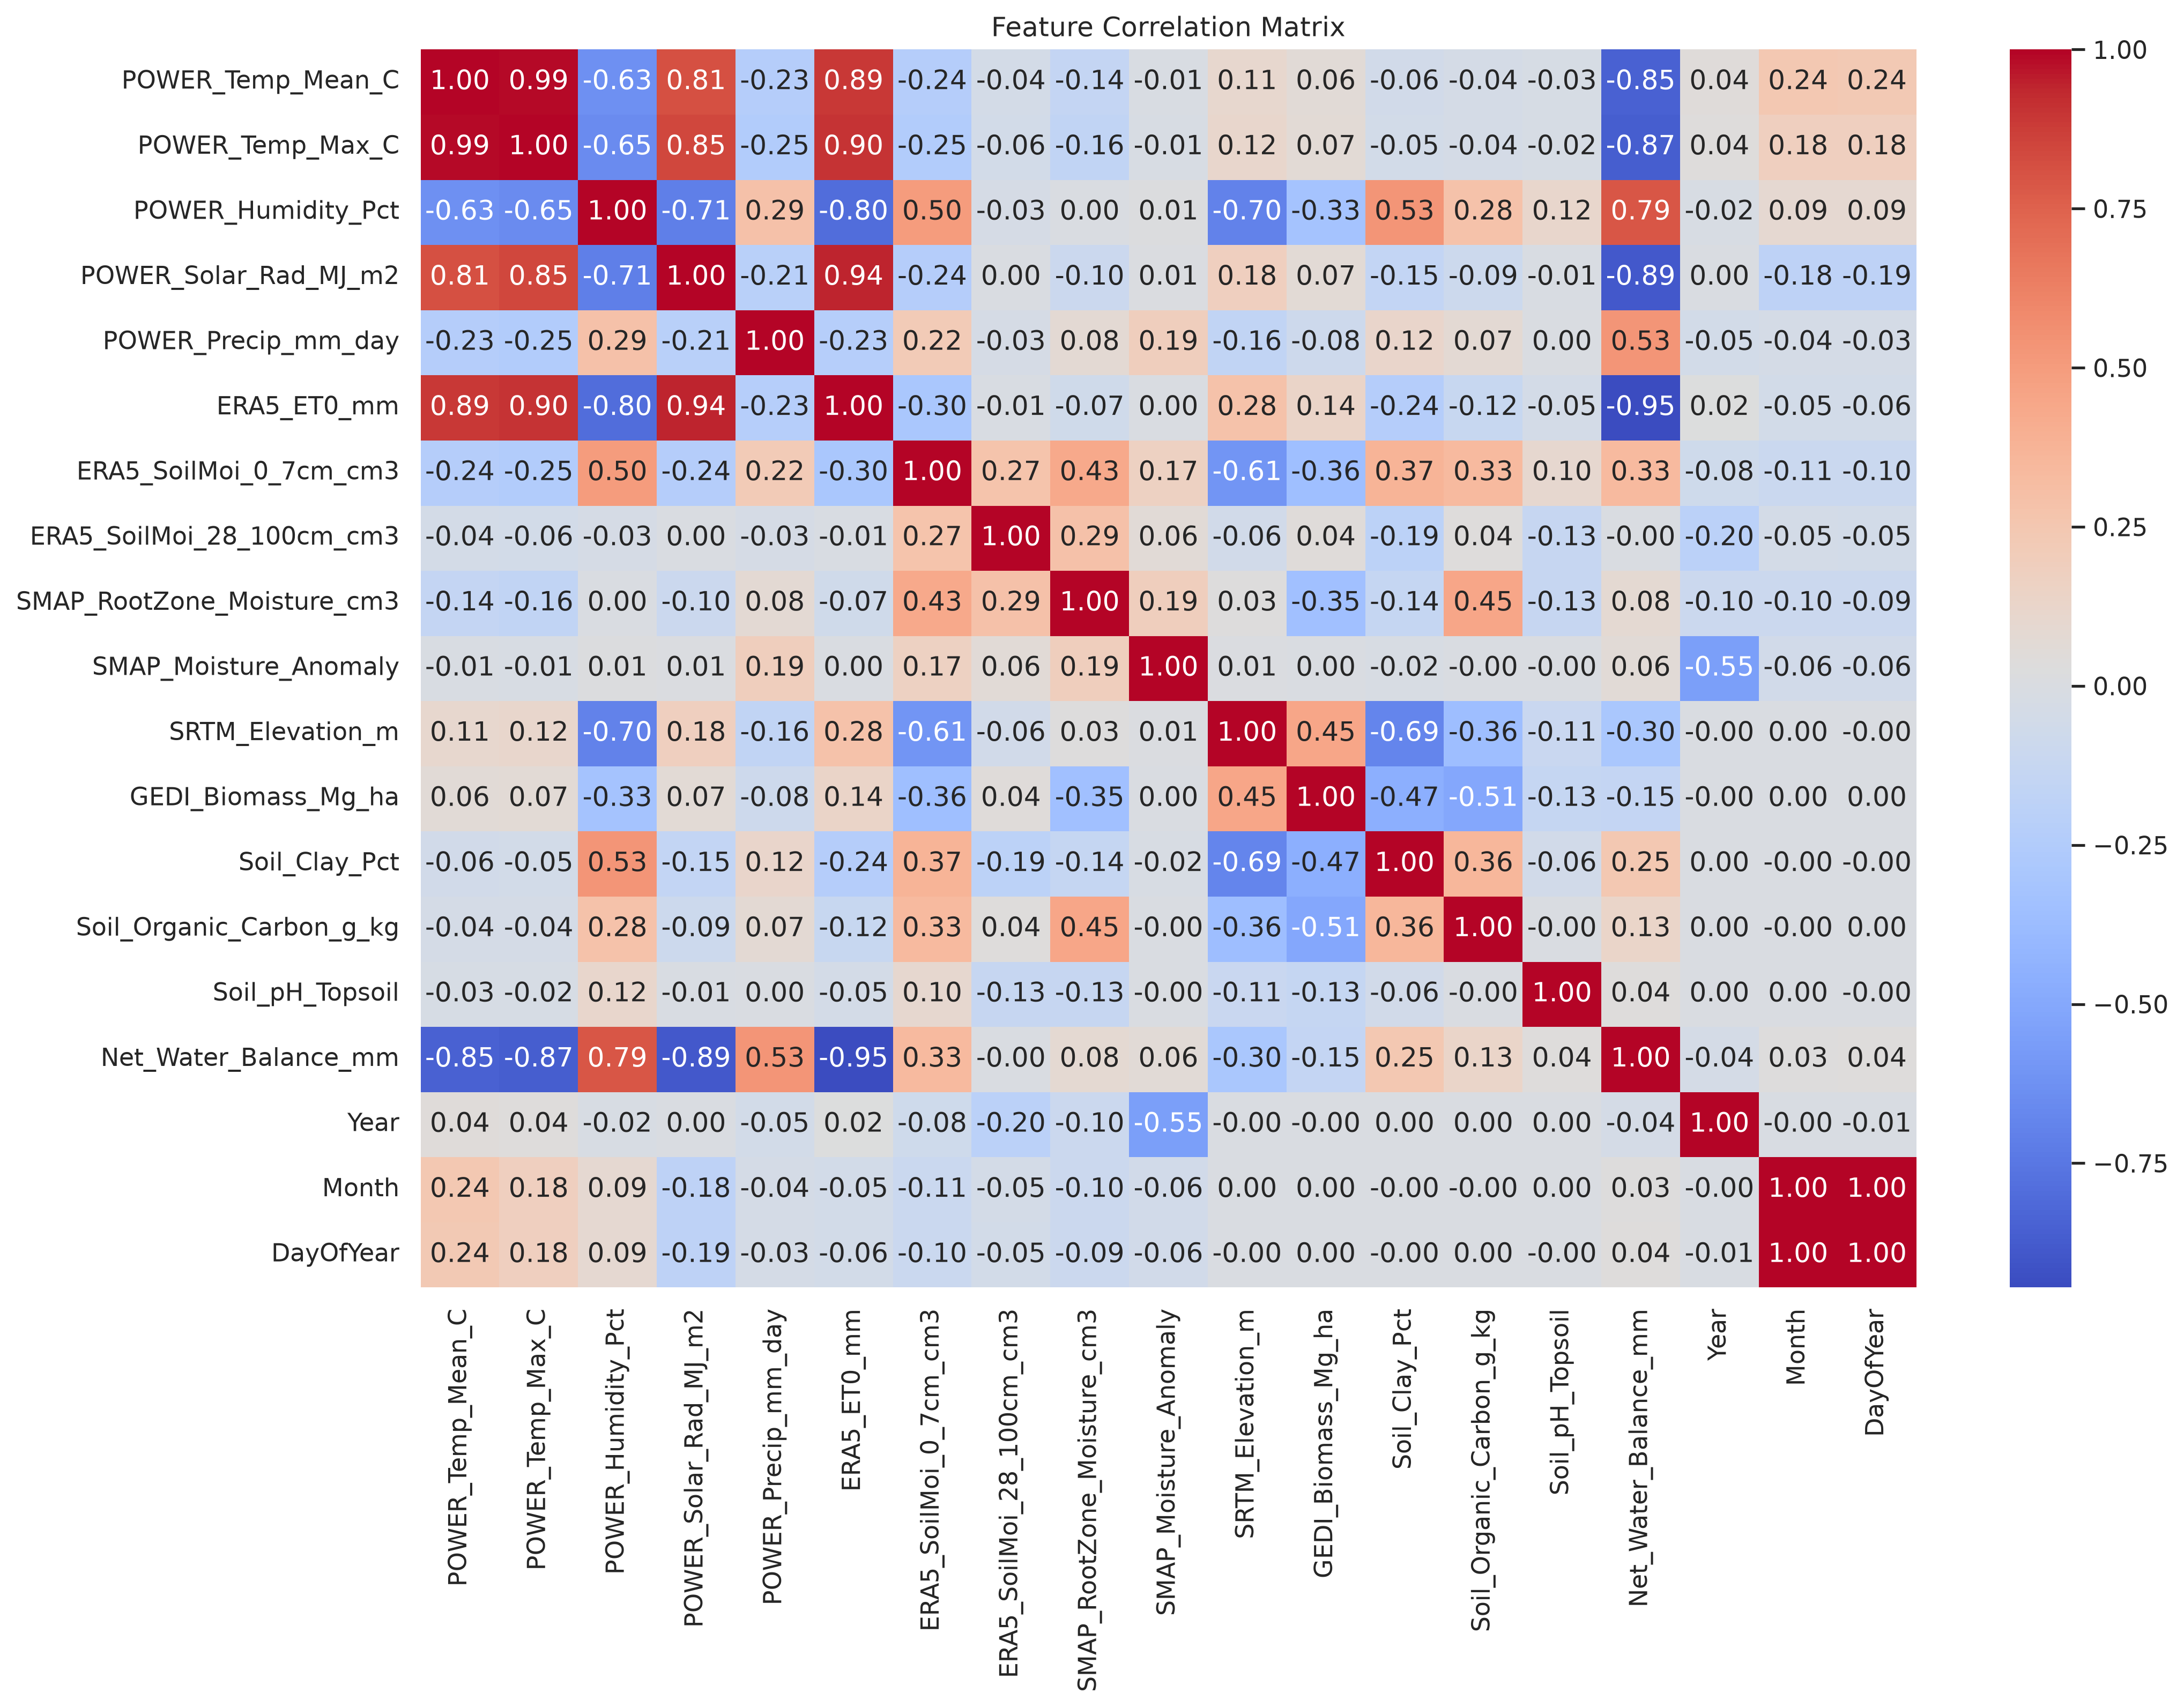

In [94]:
plt.figure(figsize=(15, 10),dpi=300)
sns.heatmap(df.corr(numeric_only=True), annot=True,fmt='.2f', cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

In [95]:
df["Lag1_SoilMoi_Surface"] = df.groupby("Governorate")["ERA5_SoilMoi_0_7cm_cm3"].shift(1)
df["Lag1_SoilMoi_Root"] = df.groupby("Governorate")["SMAP_RootZone_Moisture_cm3"].shift(1)
df["Lag1_ET0"] = df.groupby("Governorate")["ERA5_ET0_mm"].shift(1)
df["Lag1_Water_Balance"] = df.groupby("Governorate")["Net_Water_Balance_mm"].shift(1)

df["Roll3_SoilMoi_Surface"] = (
    df.groupby("Governorate")["ERA5_SoilMoi_0_7cm_cm3"]
    .transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
)

df_model = df.dropna().reset_index(drop=True)

TARGET = "ERA5_SoilMoi_0_7cm_cm3"
FEATURES = [
    "Month",
    "DayOfYear",
    "POWER_Temp_Mean_C",
    "POWER_Temp_Max_C",
    "POWER_Humidity_Pct",
    "POWER_Solar_Rad_MJ_m2",
    "POWER_Precip_mm_day",
    "ERA5_ET0_mm",
    "ERA5_SoilMoi_28_100cm_cm3",
    "SMAP_Moisture_Anomaly",
    "SRTM_Elevation_m",
    "GEDI_Biomass_Mg_ha",
    "Soil_Clay_Pct",
    "Soil_Organic_Carbon_g_kg",
    "Soil_pH_Topsoil",
    "Net_Water_Balance_mm",
    "Lag1_SoilMoi_Surface",
    "Lag1_SoilMoi_Root",
    "Lag1_ET0",
    "Lag1_Water_Balance",
    "Roll3_SoilMoi_Surface",
]

train_df = df_model[df_model["Year"] <= 2023].copy()
test_df = df_model[df_model["Year"] >= 2024].copy()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

In [96]:
model_comparison_df = pd.DataFrame()

def evaluate_and_plot_model(
    model,
    model_name,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test,
    feature_names=train_df.columns
):
    global model_comparison_df

    y_train_pred_raw = model.predict(X_train)
    y_test_pred_raw = model.predict(X_test)

    y_train_real = np.expm1(y_train)
    y_train_pred_real = np.expm1(y_train_pred_raw)
    y_test_real = np.expm1(y_test)
    y_test_pred_real = np.expm1(y_test_pred_raw)

    y_train_arr = np.array(y_train_real).ravel()
    y_train_pred_arr = np.array(y_train_pred_real).ravel()
    y_test_arr = np.array(y_test_real).ravel()
    y_test_pred_arr = np.array(y_test_pred_real).ravel()

    train_residuals = y_train_arr - y_train_pred_arr
    test_residuals = y_test_arr - y_test_pred_arr

    r2_train = r2_score(y_train_arr, y_train_pred_arr) * 100
    r2_test = r2_score(y_test_arr, y_test_pred_arr) * 100
    r2_gap = r2_train - r2_test

    mae_train = mean_absolute_error(y_train_arr, y_train_pred_arr)
    mae_test = mean_absolute_error(y_test_arr, y_test_pred_arr)

    rmse_train = np.sqrt(mean_squared_error(y_train_arr, y_train_pred_arr))
    rmse_test = np.sqrt(mean_squared_error(y_test_arr, y_test_pred_arr))

    metrics_dict = {
        'Model Name': model_name,
        'R2 Train (%)': r2_train,
        'R2 Test (%)': r2_test,
        'R2 Gap (%)': r2_gap,
        'MAE Train': mae_train,
        'MAE Test': mae_test,
        'RMSE Train': rmse_train,
        'RMSE Test': rmse_test,
    }

    current_df = pd.DataFrame([metrics_dict])
    model_comparison_df = pd.concat(
        [model_comparison_df, current_df], ignore_index=True
    ).drop_duplicates(subset=['Model Name'], keep='last')

    print(f"\n{'='*25} {model_name} Generalization Diagnostics {'='*25}")
    print(f"Train R²: {r2_train:.2f}% | Test R²: {r2_test:.2f}% | Overfitting Gap: {r2_gap:+.2f}%")
    print(f"Train MAE: {mae_train:,.2f} | Test MAE: {mae_test:,.2f}")
    print(f"Train RMSE: {rmse_train:,.2f} | Test RMSE: {rmse_test:,.2f}")
    print('='*75)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor='#FFFFFF')
    fig.suptitle(f'Performance Diagnostics: {model_name} (Train vs Test Comparison)', 
                 fontsize=15, fontweight='bold', color='#0F172A', y=0.98)

    axes[0].scatter(
        y_train_arr, y_train_pred_arr,
        color='#94A3B8', alpha=0.25, s=20, edgecolors='none', label=f'Train Data (R²: {r2_train:.1f}%)'
    )
    sc = axes[0].scatter(
        y_test_arr, y_test_pred_arr,
        c=np.abs(test_residuals), cmap='plasma', alpha=0.75, s=35, edgecolors='none', label=f'Test Data (R²: {r2_test:.1f}%)'
    )
    
    min_val = min(y_test_arr.min(), y_train_arr.min())
    max_val = max(y_test_arr.max(), y_train_arr.max())
    axes[0].plot([min_val, max_val], [min_val, max_val], color='#EF4444', linestyle='--', linewidth=2.0, label='Ideal 45° Line')

    axes[0].set_title('Actual vs Predicted Parity Plot', fontsize=12, fontweight='bold', color='#1E293B', pad=10)
    axes[0].set_xlabel('Actual Real Values', fontsize=10, fontweight='bold')
    axes[0].set_ylabel('Predicted Real Values', fontsize=10, fontweight='bold')
    axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[0].grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
    axes[0].legend(frameon=True, facecolor='white', edgecolor='#E2E8F0', loc='upper left')
    
    cb = plt.colorbar(sc, ax=axes[0], pad=0.02)
    cb.set_label('Absolute Test Error', fontsize=9)

    sns.kdeplot(
        train_residuals, ax=axes[1], color='#64748B', linestyle='--', linewidth=2, label='Train Residuals'
    )
    sns.histplot(
        test_residuals, ax=axes[1], bins=40, kde=True, color='#2563EB', stat="density", alpha=0.5, edgecolor='white', label='Test Residuals'
    )
    axes[1].axvline(0, color='#EF4444', linestyle=':', linewidth=1.5, label='Zero Error Target')

    axes[1].set_title('Residual Density Spread: Bias & Variance Check', fontsize=12, fontweight='bold', color='#1E293B', pad=10)
    axes[1].set_xlabel('Residual Error (Actual - Predicted)', fontsize=10, fontweight='bold')
    axes[1].set_ylabel('Probability Density', fontsize=10, fontweight='bold')
    axes[1].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    axes[1].grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
    axes[1].legend(frameon=True, facecolor='white', edgecolor='#E2E8F0', loc='upper right')

    plt.tight_layout()
    plt.show()

    plot_interactive_specifics(
        model, model_name, X_train, y_train, feature_names
    )

    styled_df = current_df.style.format({
        'R2 Train (%)': '{:.2f}%',
        'R2 Test (%)': '{:.2f}%',
        'R2 Gap (%)': '{:+.2f}%',
        'MAE Train': '{:,.2f}',
        'MAE Test': '{:,.2f}',
        'RMSE Train': '{:,.2f}',
        'RMSE Test': '{:,.2f}',
    }).background_gradient(cmap='Blues', subset=['R2 Test (%)'])\
      .background_gradient(cmap='Reds', subset=['R2 Gap (%)'])

    return styled_df


def plot_interactive_specifics(
    model, model_name, X_train=None, y_train=None, feature_names=None
):
    if X_train is not None and hasattr(X_train, 'shape'):
        expected_len = X_train.shape[1]
        if feature_names is None or len(feature_names) != expected_len:
            if hasattr(X_train, 'columns'):
                feature_names = list(X_train.columns)
            else:
                feature_names = [f'Feature {i}' for i in range(expected_len)]

    if model.__class__.__name__ == 'MLPRegressor':
        fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), facecolor='#FFFFFF')
        fig.suptitle(f'Neural Architecture Diagnostics: {model_name}', fontsize=14, fontweight='bold', color='#0F172A', y=1.02)

        if hasattr(model, 'loss_curve_'):
            axes[0].plot(model.loss_curve_, color='#2563EB', linewidth=2.2, label='Training Loss')
            axes[0].set_title('Optimization Loss Convergence Trajectory', fontsize=12, fontweight='bold', pad=10)
            axes[0].set_xlabel('Epoch / Iterations', fontsize=10, fontweight='bold')
            axes[0].set_ylabel('Loss Metric (MSE / Log-Loss)', fontsize=10, fontweight='bold')
            axes[0].grid(True, linestyle='--', alpha=0.5, color='#CBD5E1')
            
            final_loss = model.loss_curve_[-1]
            axes[0].scatter(len(model.loss_curve_) - 1, final_loss, color='#EF4444', s=60, zorder=5)
            axes[0].annotate(f'Final Loss: {final_loss:.4f}', 
                             xy=(len(model.loss_curve_) - 1, final_loss),
                             xytext=(-80, 15), textcoords='offset points',
                             bbox=dict(boxstyle="round,pad=0.3", fc="#FEF2F2", ec="#EF4444", lw=1),
                             arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=.2", color="#EF4444"))
            axes[0].legend(frameon=True, facecolor='white', edgecolor='#E2E8F0')

        if hasattr(model, 'coefs_'):
            layer_weights = [np.abs(w).ravel() for w in model.coefs_]
            layer_labels = [f'Layer {i}→{i+1}\n({w.shape[0]}x{w.shape[1]})' for i, w in enumerate(model.coefs_)]
            
            vp = axes[1].violinplot(layer_weights, showmeans=True, showmedians=False)
            for body in vp['bodies']:
                body.set_facecolor('#8B5CF6')
                body.set_edgecolor('#5B21B6')
                body.set_alpha(0.6)
            vp['cmeans'].set_color('#1E293B')
            
            axes[1].set_xticks(range(1, len(layer_labels) + 1))
            axes[1].set_xticklabels(layer_labels, fontsize=9)
            axes[1].set_title('Synaptic Weight Magnitude Distribution (|W|)', fontsize=12, fontweight='bold', pad=10)
            axes[1].set_xlabel('Inter-Layer Synapses', fontsize=10, fontweight='bold')
            axes[1].set_ylabel('Absolute Weight Values', fontsize=10, fontweight='bold')
            axes[1].grid(True, linestyle='--', alpha=0.5, color='#CBD5E1', axis='y')

        plt.tight_layout()
        plt.show()
        return

    elif hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
        total_imp = importances.sum()
        pct_importances = (importances / total_imp) * 100 if total_imp > 0 else importances

        valid_names = (
            list(feature_names) 
            if (feature_names is not None and len(feature_names) == len(importances)) 
            else [f'Feature {i}' for i in range(len(importances))]
        )

        imp_df = (
            pd.DataFrame({
                'Feature': valid_names,
                'Importance': importances,
                'Percentage': pct_importances,
            })
            .sort_values(by='Importance', ascending=True)
            .tail(15)
        )

        fig, ax = plt.subplots(figsize=(12, 6.5), facecolor='#FFFFFF')
        ax.set_facecolor('#F8FAFC')
        
        norm = plt.Normalize(imp_df['Importance'].min(), imp_df['Importance'].max())
        colors = [plt.cm.plasma(norm(val)) for val in imp_df['Importance']]
        
        bars = ax.barh(imp_df['Feature'], imp_df['Importance'], color=colors, edgecolor='#0F172A', linewidth=0.5, height=0.65)
        
        for bar, val, pct in zip(bars, imp_df['Importance'], imp_df['Percentage']):
            ax.text(
                val + (imp_df['Importance'].max() * 0.012), 
                bar.get_y() + bar.get_height() / 2, 
                f'{val:.3f} ({pct:.1f}%)', 
                va='center', ha='left', fontsize=9.5, color='#0F172A', fontweight='medium'
            )

        ax.set_title(f'Top 15 Feature Importances — {model_name}', fontsize=13, fontweight='bold', color='#0F172A', pad=15)
        ax.set_xlabel('Importance Weight', fontsize=10, fontweight='bold')
        ax.set_xlim(0, imp_df['Importance'].max() * 1.22)
        ax.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1', axis='x')
        
        plt.tight_layout()
        plt.show()

    elif hasattr(model, 'coef_'):
        coefs = model.coef_.ravel()
        
        valid_names = (
            list(feature_names) 
            if (feature_names is not None and len(feature_names) == len(coefs)) 
            else [f'Feature {i}' for i in range(len(coefs))]
        )

        coef_df = (
            pd.DataFrame({
                'Feature': valid_names,
                'Coefficient': coefs,
                'AbsCoef': np.abs(coefs),
            })
            .sort_values(by='AbsCoef', ascending=True)
            .tail(15)
        )

        fig, ax = plt.subplots(figsize=(12, 6.5), facecolor='#FFFFFF')
        ax.set_facecolor('#F8FAFC')

        norm = plt.Normalize(coef_df['Coefficient'].min(), coef_df['Coefficient'].max())
        colors = [plt.cm.coolwarm(norm(val)) for val in coef_df['Coefficient']]
        
        bars = ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='#0F172A', linewidth=0.5, height=0.65)
        
        for bar, c in zip(bars, coef_df['Coefficient']):
            offset = np.abs(coef_df['Coefficient'].max() - coef_df['Coefficient'].min()) * 0.015
            pos_x = c + offset if c >= 0 else c - offset
            ha_align = 'left' if c >= 0 else 'right'
            ax.text(
                pos_x, 
                bar.get_y() + bar.get_height() / 2, 
                f'{c:,.3f}', 
                va='center', ha=ha_align, fontsize=9.5, color='#0F172A', fontweight='medium'
            )

        ax.axvline(0, color='#475569', linewidth=1.0, linestyle='--')
        ax.set_title(f'Top 15 Feature Elasticity Coefficients — {model_name}', fontsize=13, fontweight='bold', color='#0F172A', pad=15)
        ax.set_xlabel('Coefficient Impact', fontsize=10, fontweight='bold')
        
        max_abs = max(abs(coef_df['Coefficient'].min()), abs(coef_df['Coefficient'].max())) * 1.25
        ax.set_xlim(-max_abs if coef_df['Coefficient'].min() < 0 else 0, max_abs)
        ax.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1', axis='x')

        plt.tight_layout()
        plt.show()

    if hasattr(model, 'tree_') or model.__class__.__name__ == 'DecisionTreeRegressor':
        from sklearn.tree import plot_tree
        plt.figure(figsize=(16, 8), facecolor='#FFFFFF')
        
        valid_names = (
            list(feature_names) 
            if (feature_names is not None and hasattr(model, 'n_features_in_') and len(feature_names) == model.n_features_in_) 
            else None
        )
        
        plot_tree(
            model,
            max_depth=3,
            feature_names=valid_names,
            filled=True,
            rounded=True,
            fontsize=9,
        )
        plt.title(f'Decision Logic Path (Max Depth = 3) — {model_name}', fontsize=13, fontweight='bold', color='#0F172A', pad=15)
        plt.tight_layout()
        plt.show()


def get_model_comparison_summary():
    global model_comparison_df
    return (
        model_comparison_df.sort_values(by='R2 Test (%)', ascending=False, ignore_index=True)
        .style.format({
            'R2 Train (%)': '{:.2f}%',
            'R2 Test (%)': '{:.2f}%',
            'R2 Gap (%)': '{:+.2f}%',
            'MAE Train': '{:,.2f}',
            'MAE Test': '{:,.2f}',
            'RMSE Train': '{:,.2f}',
            'RMSE Test': '{:,.2f}',
        })
        .background_gradient(cmap='Blues', subset=['R2 Test (%)'])
        .background_gradient(cmap='Reds', subset=['R2 Gap (%)'])
    )

In [97]:
lr = LinearRegression()
lr.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](21,)","[-0. , 0. , 0. ,..., 0. ,-0. , 0.38]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](21,)","['Month','DayOfYear','POWER_Temp_Mean_C',...,'Lag1_ET0', 'Lag1_Water_Balance','Roll3_SoilMoi_Surface']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.006402
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,21
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(20)



========================= Linear Regression Generalization Diagnostics =========================
Train R²: 89.95% | Test R²: 83.92% | Overfitting Gap: +6.04%
Train MAE: 0.01 | Test MAE: 0.01
Train RMSE: 0.02 | Test RMSE: 0.02


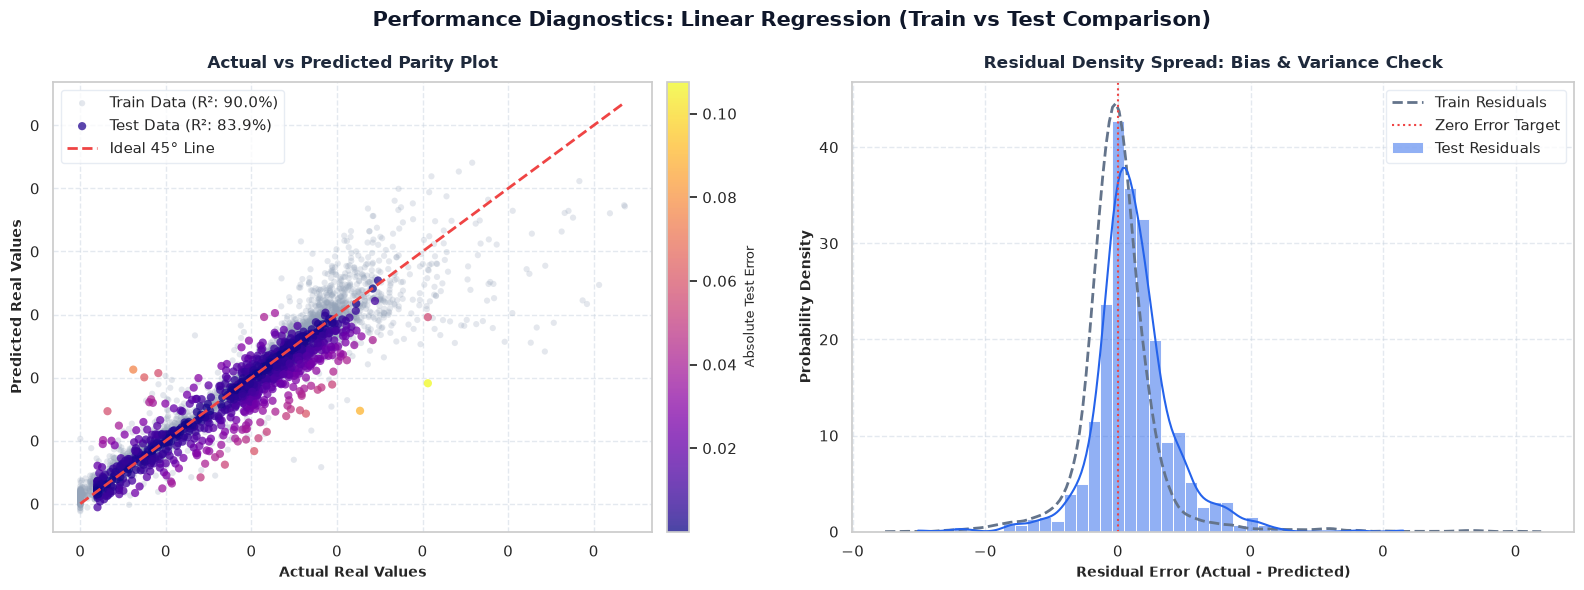

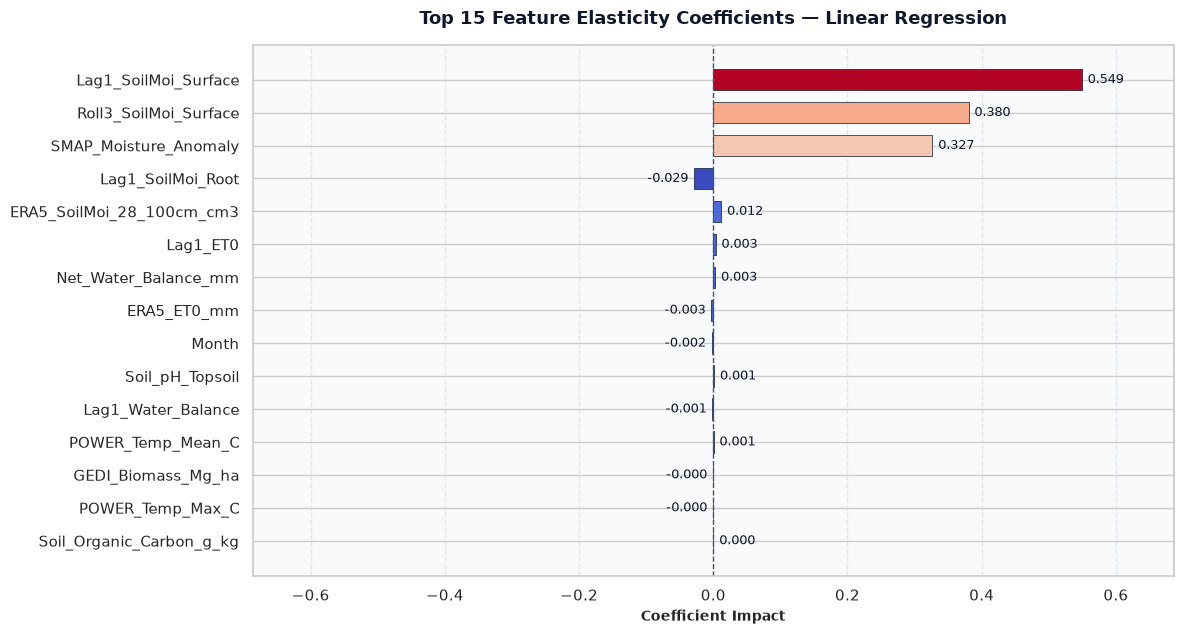

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Linear Regression,89.95%,83.92%,+6.04%,0.01,0.01,0.02,0.02


In [98]:
evaluate_and_plot_model(
    model=lr,
    model_name="Linear Regression",
)

In [99]:
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes 


========================= Decision Tree Regressor Generalization Diagnostics =========================
Train R²: 100.00% | Test R²: 81.45% | Overfitting Gap: +18.55%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.00 | Test RMSE: 0.02


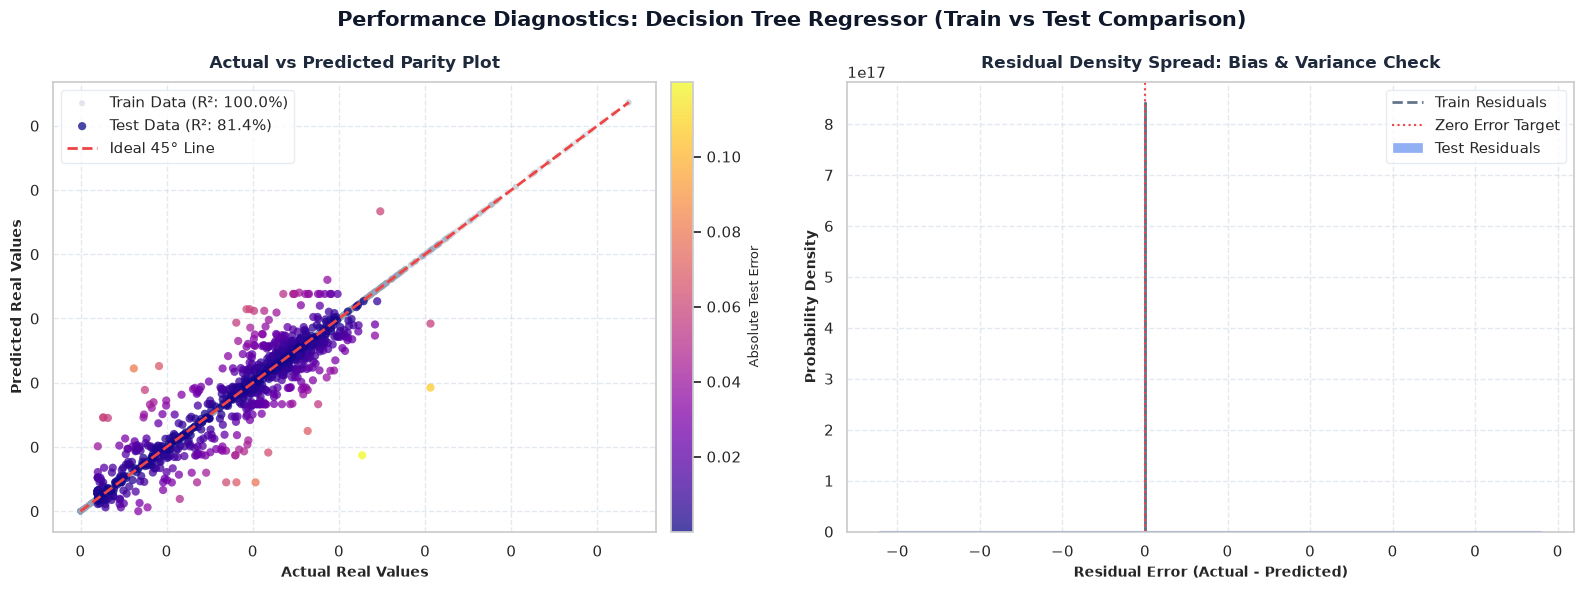

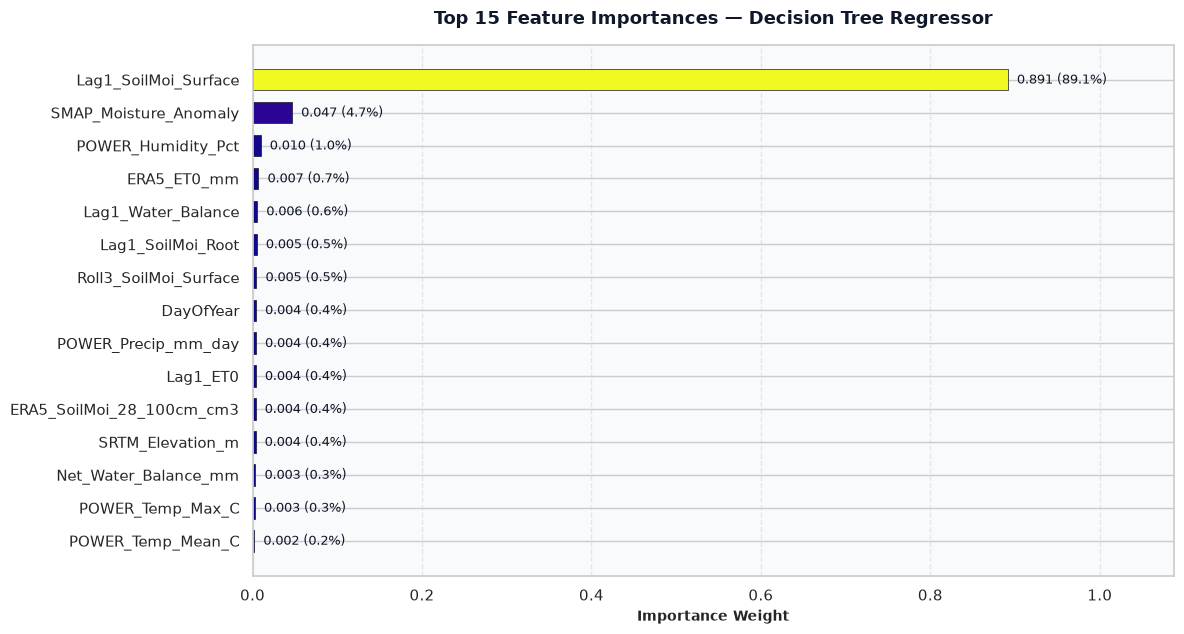

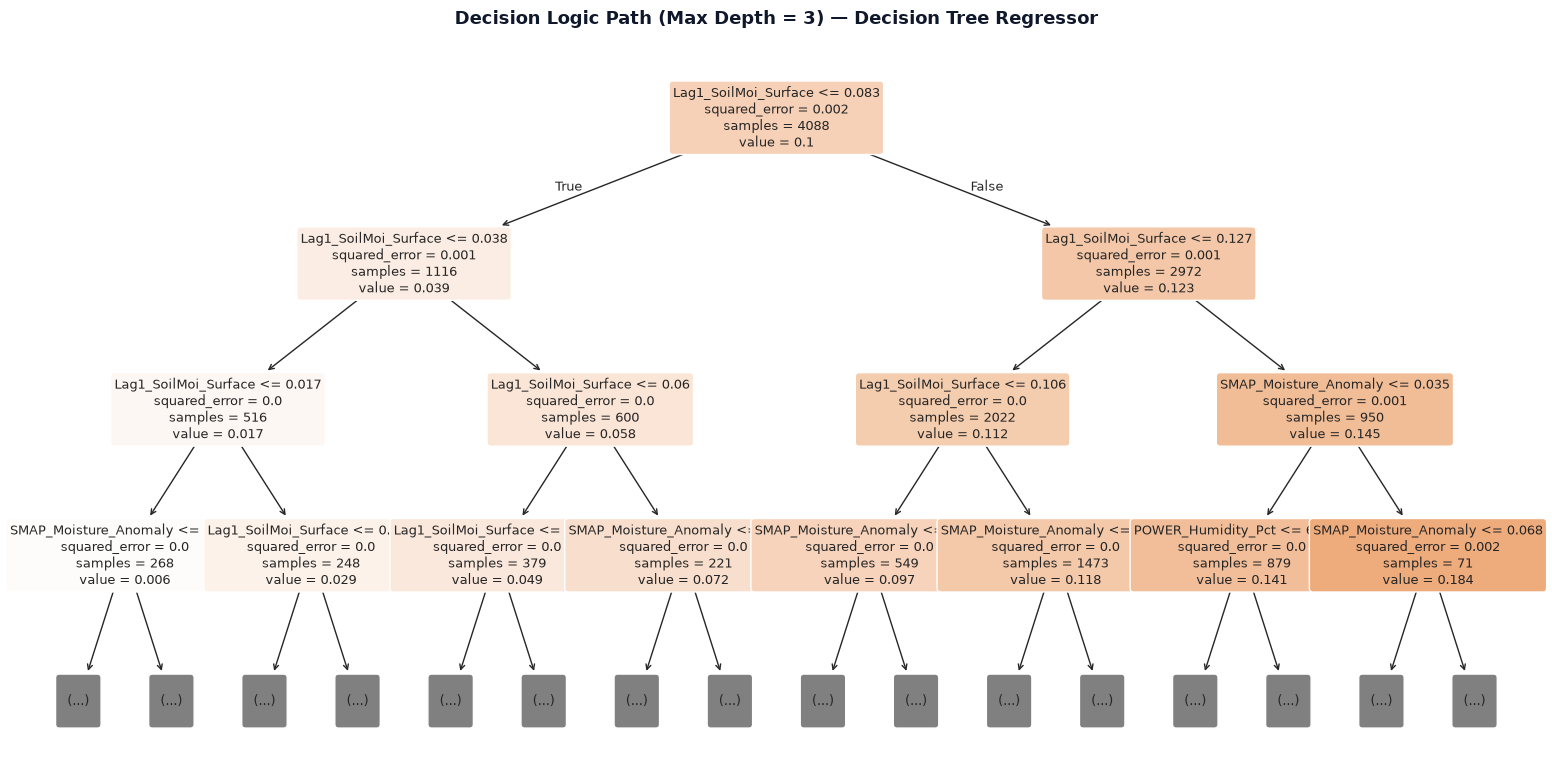

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Decision Tree Regressor,100.00%,81.45%,+18.55%,0.00,0.01,0.00,0.02


In [100]:
evaluate_and_plot_model(
    model=tree,
    model_name="Decision Tree Regressor",
)

In [101]:
forest = RandomForestRegressor(n_jobs=-1,random_state= 42)
forest.fit(X_train,y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m


========================= Random Forest Regressor Generalization Diagnostics =========================
Train R²: 99.27% | Test R²: 86.27% | Overfitting Gap: +13.00%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.00 | Test RMSE: 0.01


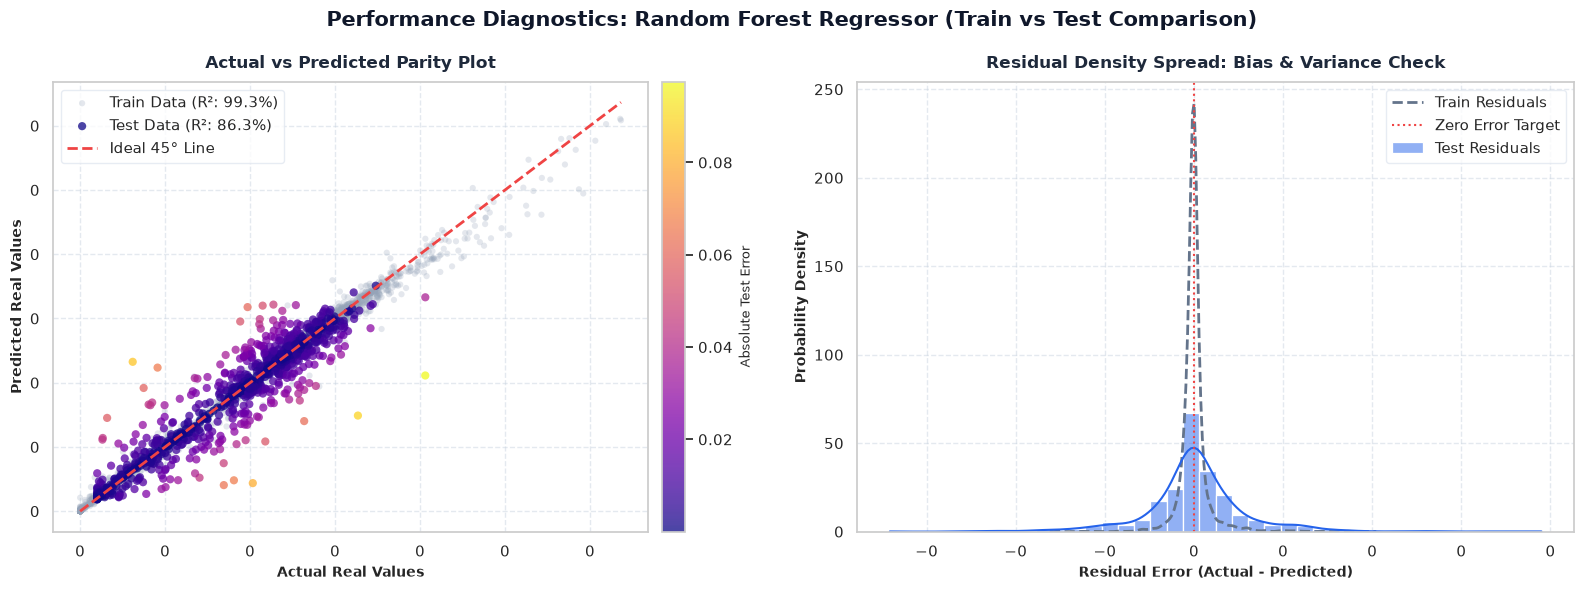

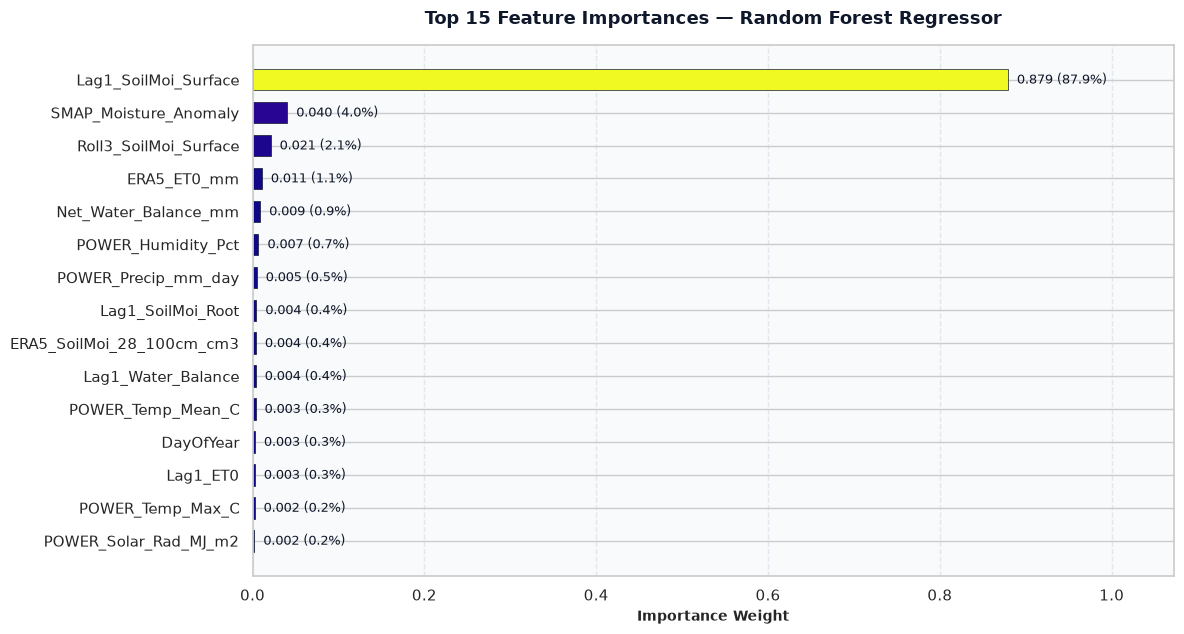

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Random Forest Regressor,99.27%,86.27%,+13.00%,0.00,0.01,0.00,0.01


In [102]:
evaluate_and_plot_model(
    model=forest,
    model_name="Random Forest Regressor",
)

In [103]:
gradient = GradientBoostingRegressor(random_state= 42)
gradient.fit(X_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf


========================= Gradient Boosting Regressor Generalization Diagnostics =========================
Train R²: 97.20% | Test R²: 87.71% | Overfitting Gap: +9.49%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.01 | Test RMSE: 0.01


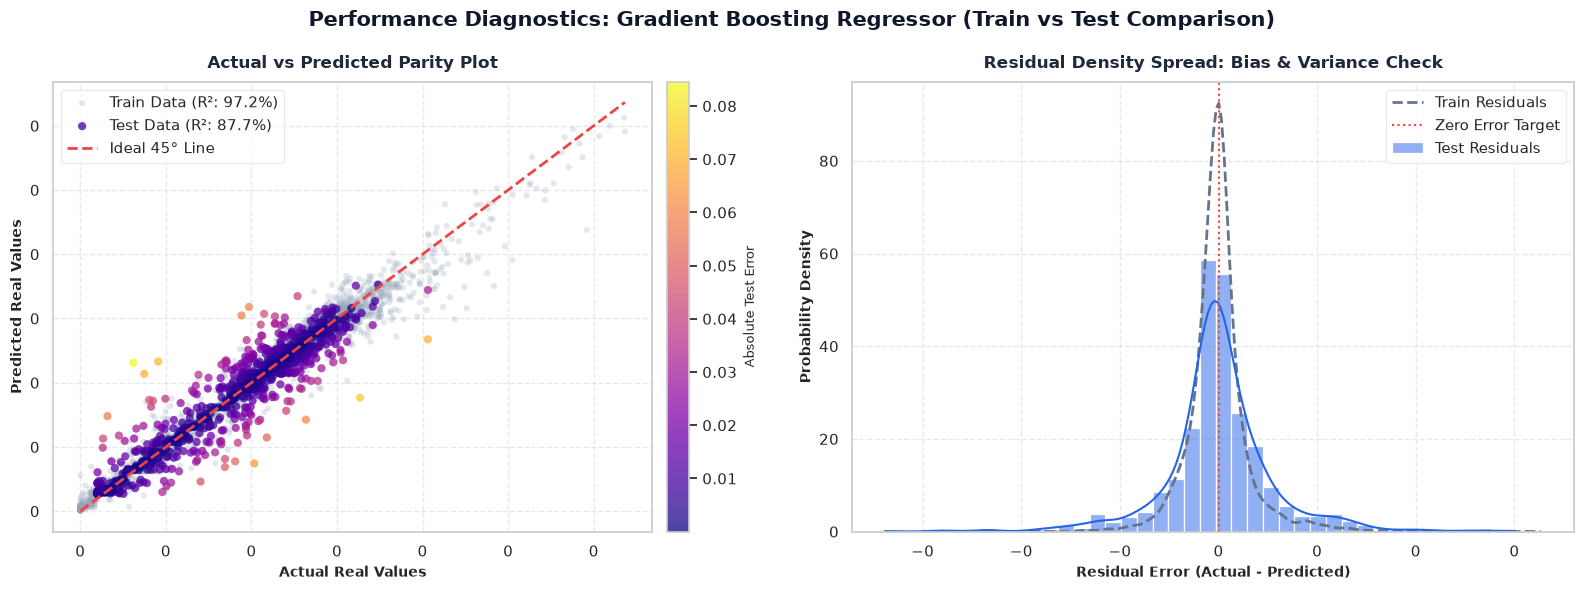

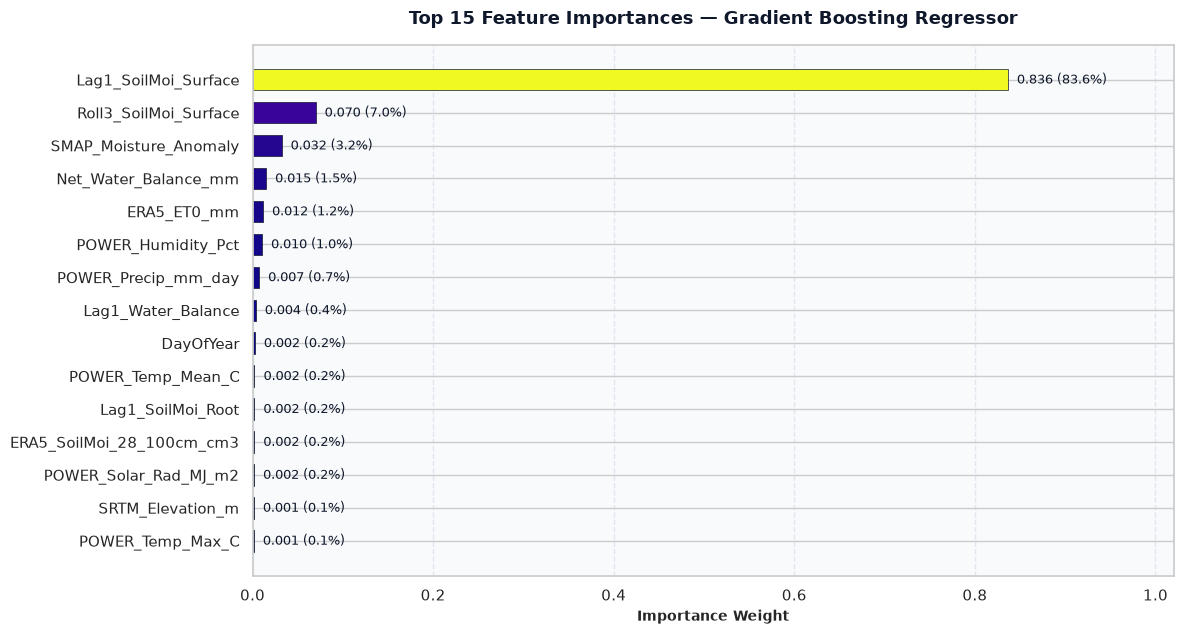

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Gradient Boosting Regressor,97.20%,87.71%,+9.49%,0.00,0.01,0.01,0.01


In [104]:
evaluate_and_plot_model(
    model=gradient,
    model_name="Gradient Boosting Regressor",
)

In [105]:
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(X_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}



========================= K Neighbors Regressor Generalization Diagnostics =========================
Train R²: 73.39% | Test R²: 34.75% | Overfitting Gap: +38.64%
Train MAE: 0.02 | Test MAE: 0.02
Train RMSE: 0.03 | Test RMSE: 0.03


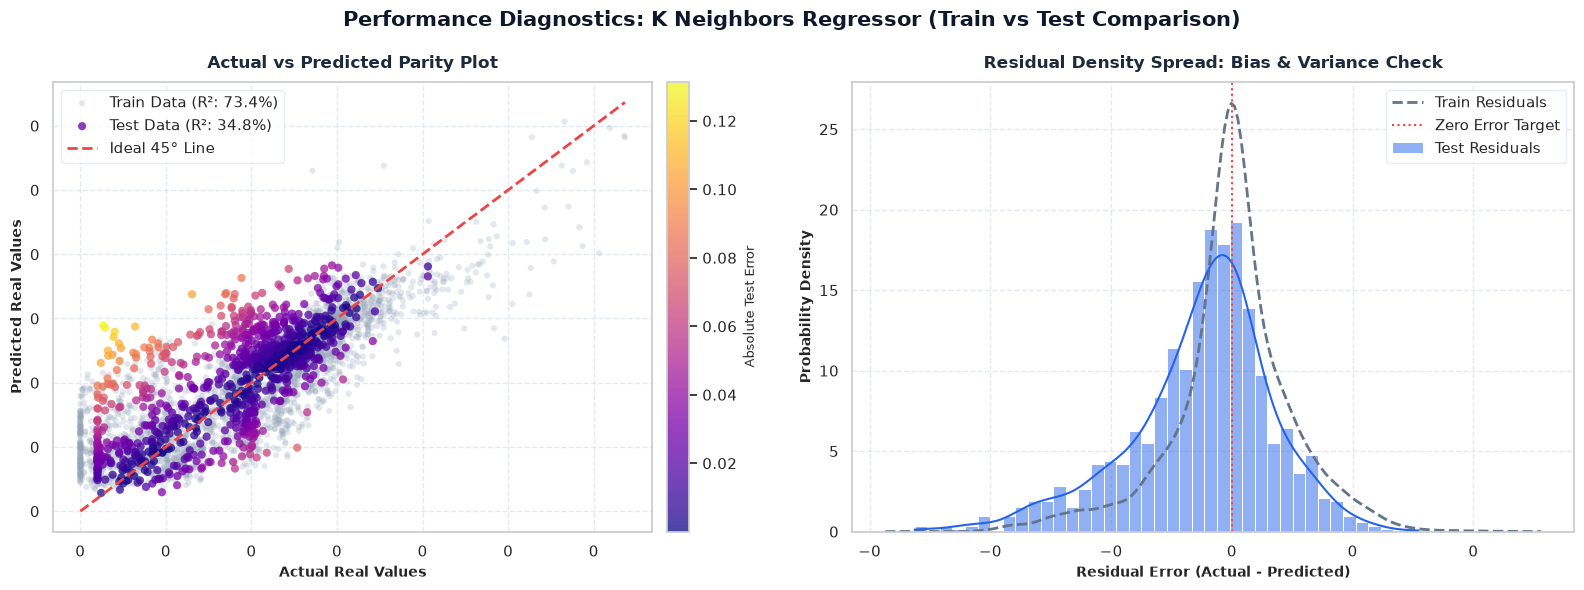

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,K Neighbors Regressor,73.39%,34.75%,+38.64%,0.02,0.02,0.03,0.03


In [106]:
evaluate_and_plot_model(
    model=knn,
    model_name="K Neighbors Regressor",
)

In [107]:
XGB =XGBRegressor(random_state= 42)
XGB.fit(X_train,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None



========================= XGB Regressor Generalization Diagnostics =========================
Train R²: 99.87% | Test R²: 85.87% | Overfitting Gap: +14.00%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.00 | Test RMSE: 0.02


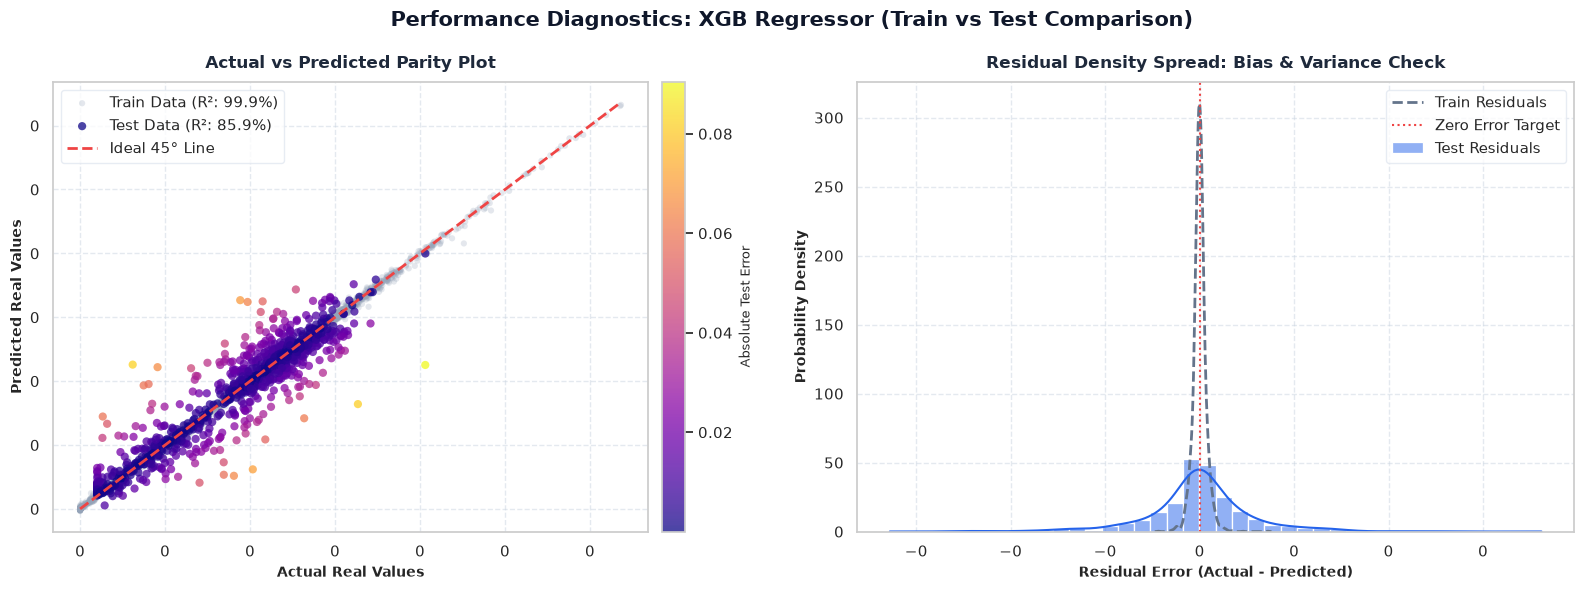

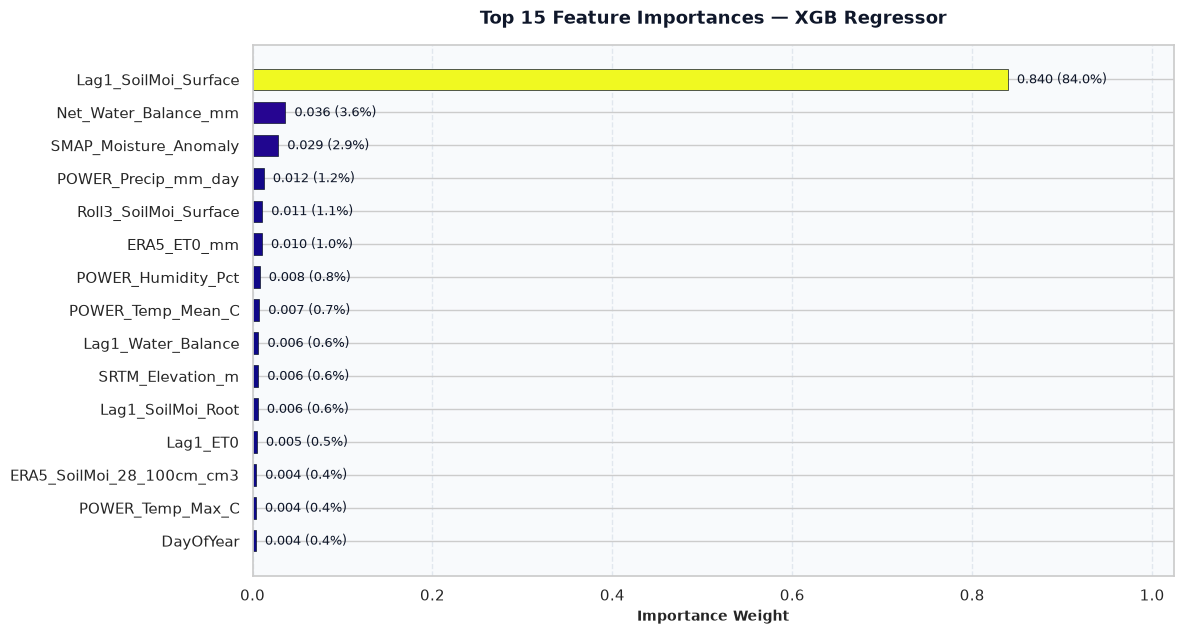

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,XGB Regressor,99.87%,85.87%,+14.00%,0.00,0.01,0.00,0.02


In [108]:
evaluate_and_plot_model(
    model=XGB,
    model_name="XGB Regressor",
)

In [109]:
lgbm =LGBMRegressor(n_jobs= -1, verbose=-1,random_state= 42)
lgbm.fit(X_train,y_train)

,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None



========================= LGBM Regressor Generalization Diagnostics =========================
Train R²: 98.95% | Test R²: 86.98% | Overfitting Gap: +11.97%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.01 | Test RMSE: 0.01


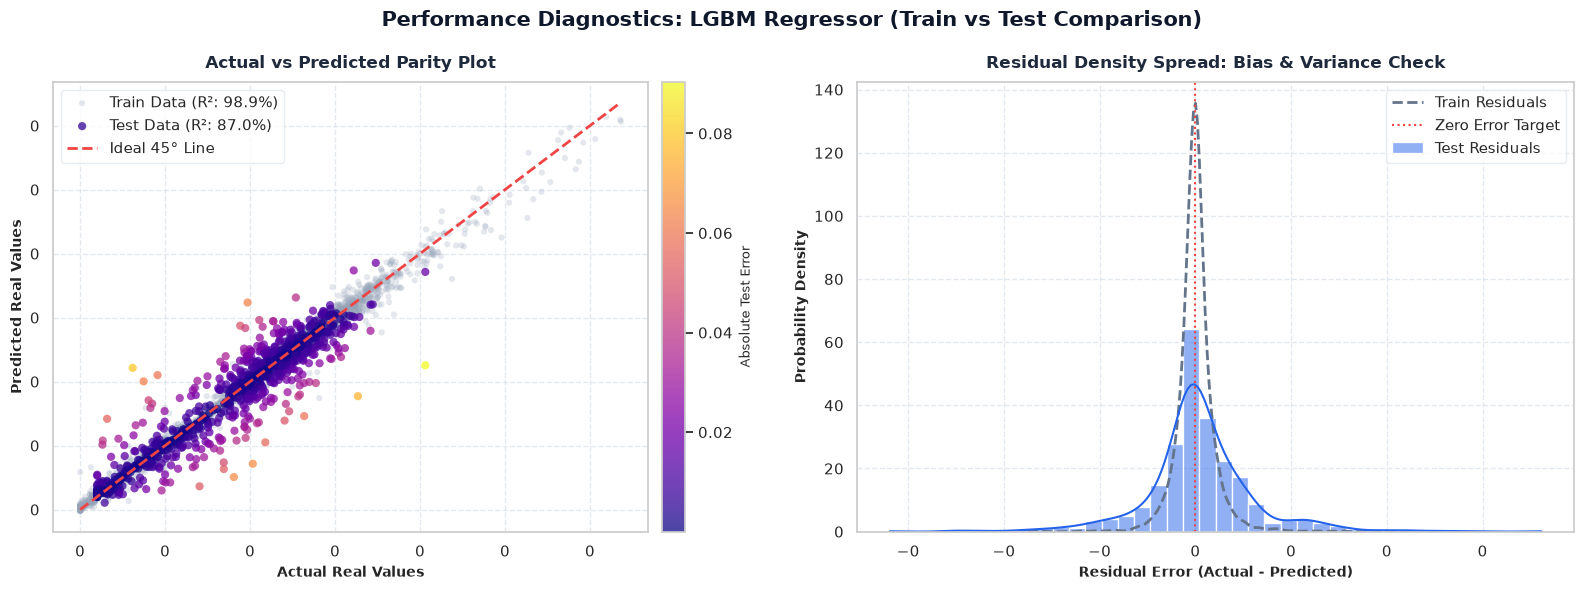

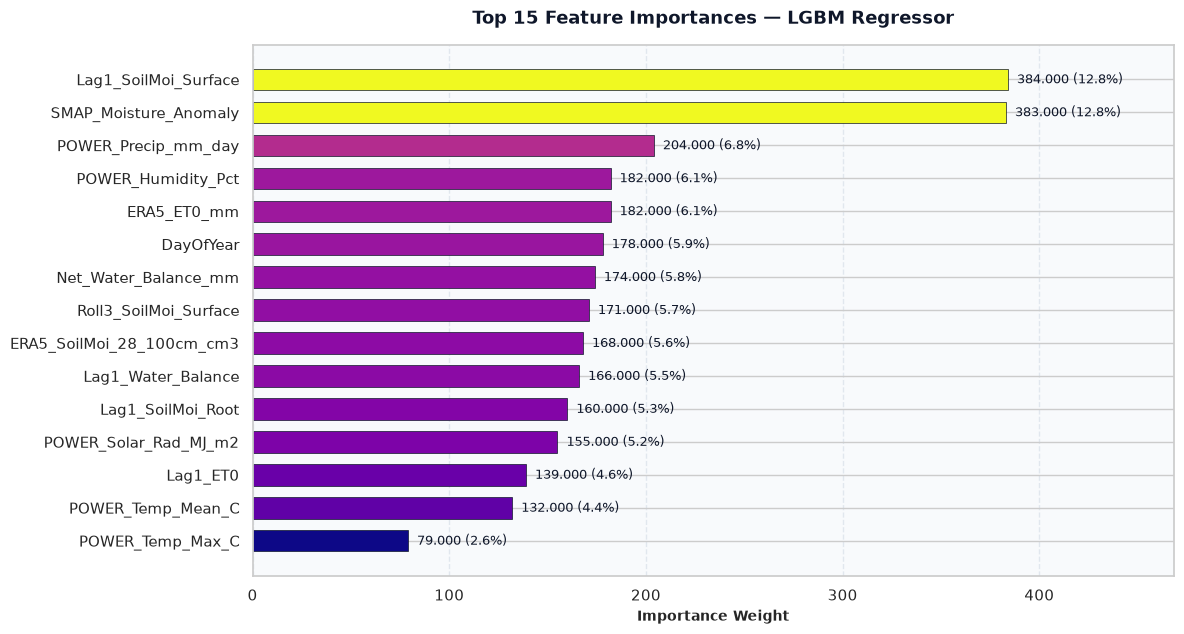

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,LGBM Regressor,98.95%,86.98%,+11.97%,0.00,0.01,0.01,0.01


In [110]:
evaluate_and_plot_model(
    model=lgbm,
    model_name="LGBM Regressor",
)

In [111]:
cat = CatBoostRegressor(verbose=0)
cat.fit(X_train,y_train)

CatBoostRegressor(loss_function='RMSE', verbose=0)


========================= CatBoost Regressor Generalization Diagnostics =========================
Train R²: 99.41% | Test R²: 87.78% | Overfitting Gap: +11.63%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.00 | Test RMSE: 0.01


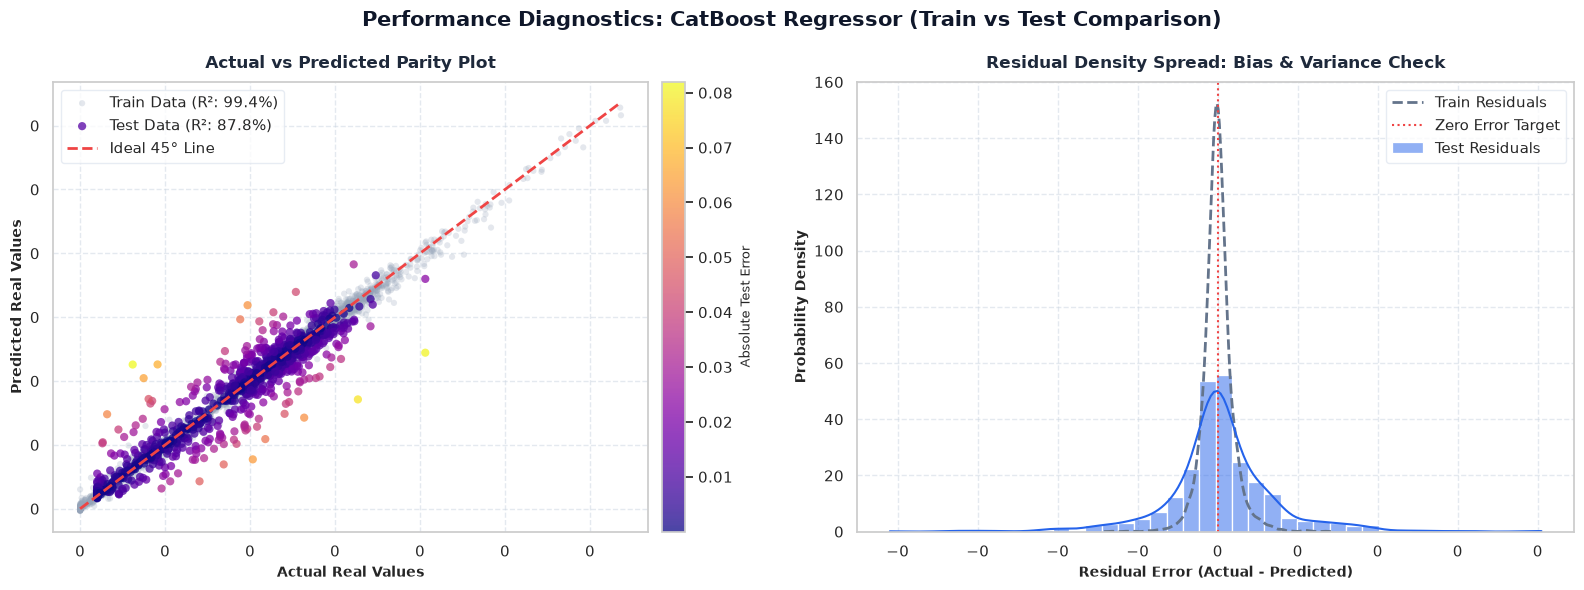

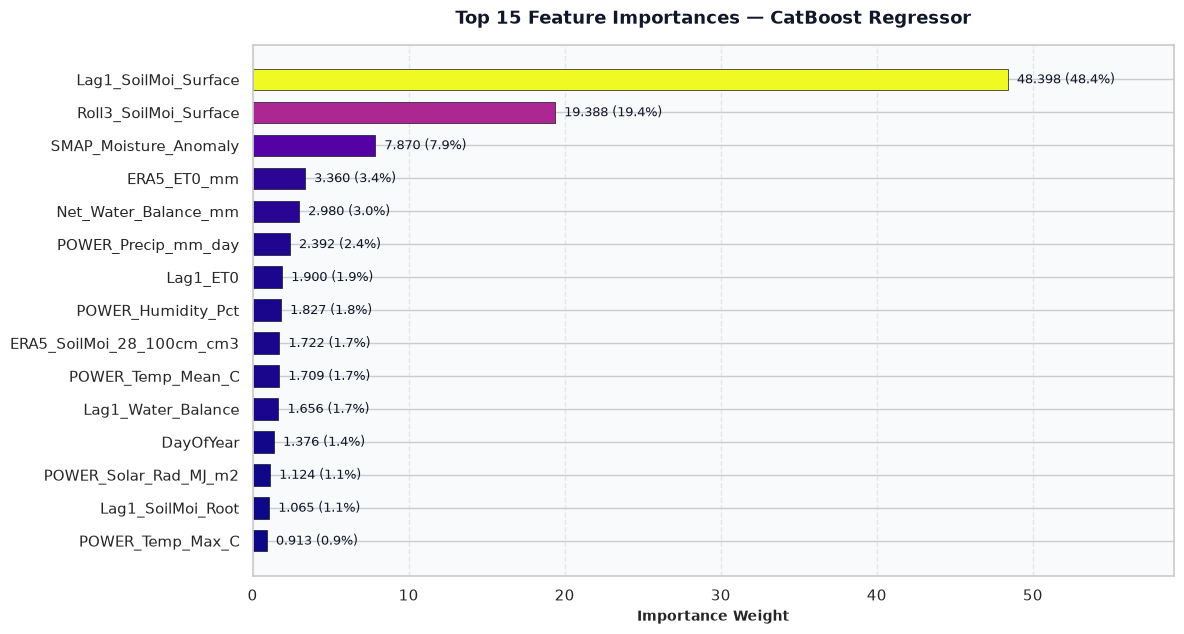

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,CatBoost Regressor,99.41%,87.78%,+11.63%,0.00,0.01,0.00,0.01


In [112]:
evaluate_and_plot_model(
    model=cat,
    model_name="CatBoost Regressor",
)

In [113]:
mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64, 32),
    activation="relu",
    solver="adam",
    alpha=0.0001,
    batch_size=256,
    learning_rate="adaptive",
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.2,
    n_iter_no_change=20,
    random_state=42,
    verbose=True
)
mlp.fit(X_train,y_train)

Iteration 1, loss = 272.35363834
Validation score: -28717.659240
Iteration 2, loss = 21.15850582
Validation score: -2182.914282
Iteration 3, loss = 4.12911253
Validation score: -324.044622
Iteration 4, loss = 0.99118712
Validation score: -233.342764
Iteration 5, loss = 0.33272892
Validation score: -180.221116
Iteration 6, loss = 0.16843117
Validation score: -121.286685
Iteration 7, loss = 0.10543468
Validation score: -88.141480
Iteration 8, loss = 0.07510376
Validation score: -68.180949
Iteration 9, loss = 0.06033173
Validation score: -59.522497
Iteration 10, loss = 0.05351370
Validation score: -59.130324
Iteration 11, loss = 0.05005134
Validation score: -50.542362
Iteration 12, loss = 0.04604294
Validation score: -45.432235
Iteration 13, loss = 0.03666403
Validation score: -31.996354
Iteration 14, loss = 0.02638629
Validation score: -20.796838
Iteration 15, loss = 0.01769141
Validation score: -13.976501
Iteration 16, loss = 0.01411219
Validation score: -11.344727
Iteration 17, loss = 

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128, ...)"
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",256
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'adaptive'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"verbose verbose: bool, default=FalseWhether to print progress messages to stdout.",True
,"early_stopping early_stopping: bool, default=FalseWhether to use early stopping to terminate training when validationscore is not improving. If set to True, it will automatically setaside ``validation_fraction`` of training data as validation andterminate training when validation score is not improving by atleast ``tol`` for ``n_iter_no_change`` consecutive epochs.Only effective when solver='sgd' or 'adam'.",True
,"validation_fraction validation_fraction: float, default=0.1The proportion of training data to set aside as validation set forearly stopping. Must be between 0 and 1.Only used if early_stopping is True.",0.2
,"n_iter_no_change n_iter_no_change: int, default=10Maximum number of epochs to not meet ``tol`` improvement.Only effective when solver='sgd' or 'adam'... versionadded:: 0.20",20
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'



========================= MLP Regressor Generalization Diagnostics =========================
Train R²: 51.58% | Test R²: 10.61% | Overfitting Gap: +40.97%
Train MAE: 0.03 | Test MAE: 0.03
Train RMSE: 0.03 | Test RMSE: 0.04


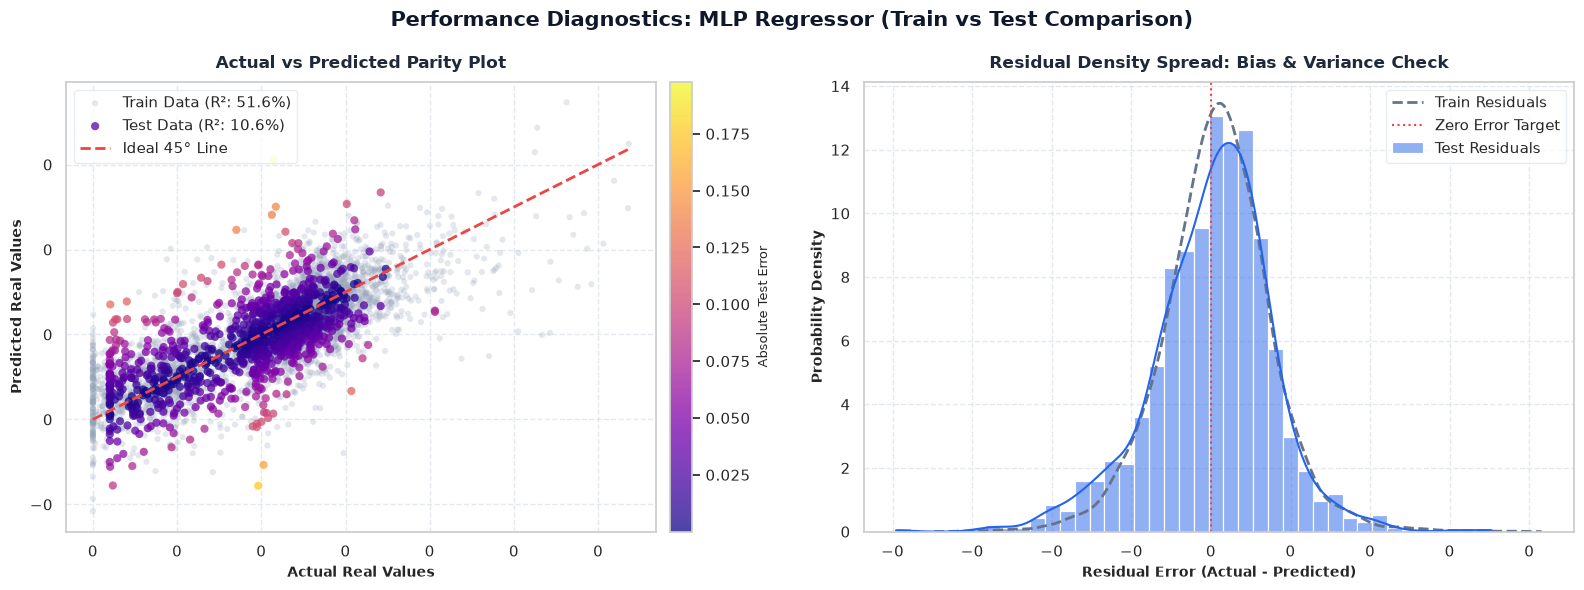

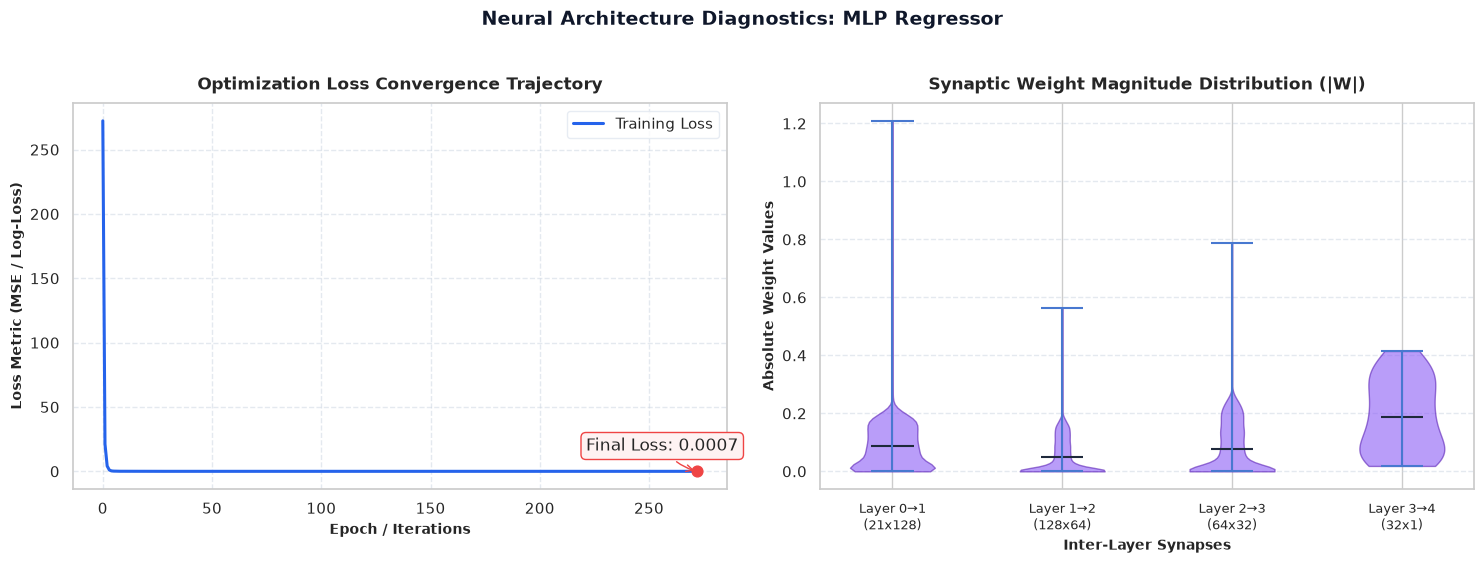

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,MLP Regressor,51.58%,10.61%,+40.97%,0.03,0.03,0.03,0.04


In [114]:
evaluate_and_plot_model(
    model=mlp,
    model_name="MLP Regressor",
)

In [115]:
vot =VotingRegressor([('cat', cat),('xgb',XGB),('linear',lr)])
vot.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingRegressor`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('cat', ...), ('xgb', ...), ...]"
,"weights weights: array-like of shape (n_regressors,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted values before averaging. Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
Name,Type,Value
estimators_ estimators_: list of regressorsThe collection of fitted sub-estimators as defined in ``estimators``that are not 'drop'.,list,"[CatBoostRegre...E', verbose=0), XGBRegressor(...ree=None, ...), LinearRegression()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Month','DayOfYear','POWER_Temp_Mean_C',...,'Lag1_ET0', 'Lag1_Water_Balance','Roll3_SoilMoi_Surface']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,21
named_estimators_ named_estimators_: :class:`~sklearn.utils.Bunch`Attribute to access any fitted sub-estimators by name... versionadded:: 0.20,Bunch,{'cat': CatBo...rRegression()}
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None



========================= Voting Regressor Generalization Diagnostics =========================
Train R²: 98.41% | Test R²: 87.43% | Overfitting Gap: +10.99%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.01 | Test RMSE: 0.01


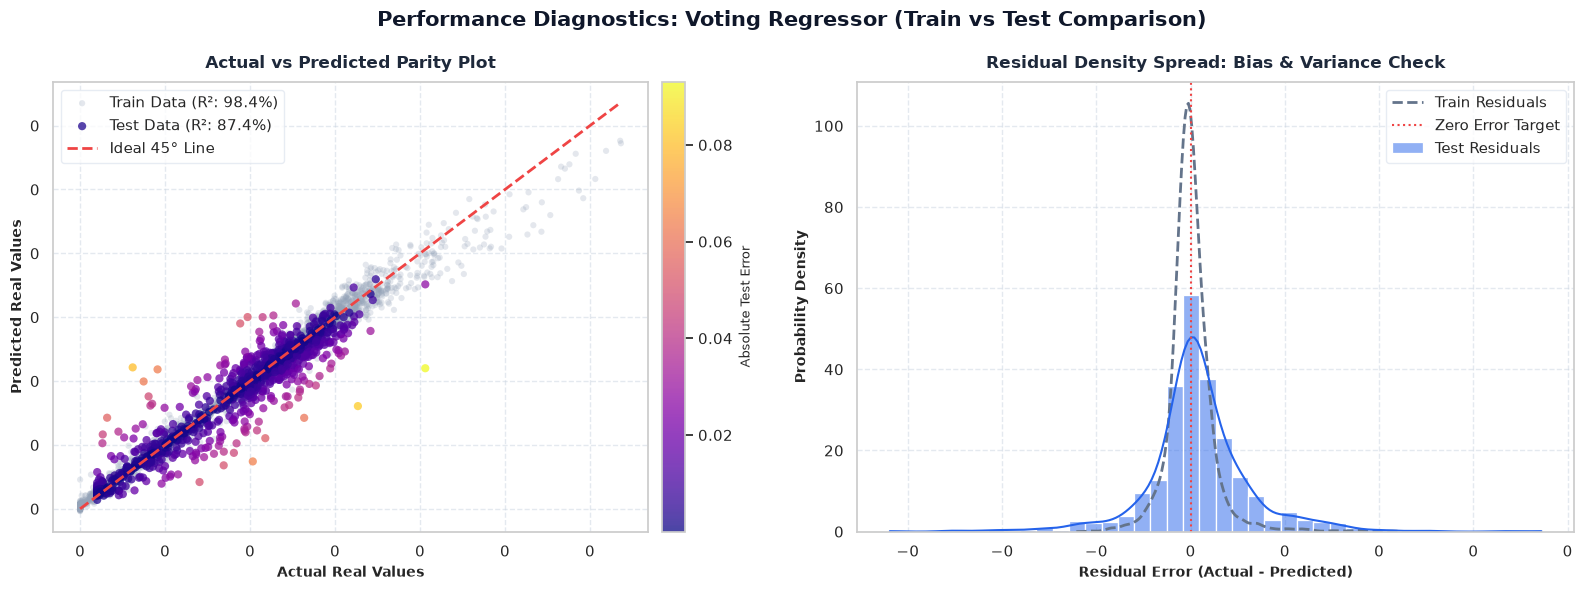

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Voting Regressor,98.41%,87.43%,+10.99%,0.00,0.01,0.01,0.01


In [116]:
evaluate_and_plot_model(
    model=vot,
    model_name="Voting Regressor",
)

In [117]:
stack =StackingRegressor(estimators=[('cat', cat),('xgb',XGB),('linear',lr)],
                         final_estimator=lr,
                         cv=5)
stack.fit(X_train,y_train)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.","[('cat', ...), ('xgb', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA regressor which will be used to combine the base estimators.The default regressor is a :class:`~sklearn.linear_model.RidgeCV`.",LinearRegression()
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[CatBoostRegre...E', verbose=0), XGBRegressor(...ree=None, ...), LinearRegression()]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Month','DayOfYear','POWER_Temp_Mean_C',...,'Lag1_ET0', 'Lag1_Water_Balance','Roll3_SoilMoi_Surface']"
final_estimator_ final_estimator_: estimatorThe regressor fit on the output of `estimators_` and responsible forfinal predictions.,LinearRegression,LinearRegression()
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 0.24,int,21



========================= Stacking Regressor Generalization Diagnostics =========================
Train R²: 99.50% | Test R²: 87.58% | Overfitting Gap: +11.93%
Train MAE: 0.00 | Test MAE: 0.01
Train RMSE: 0.00 | Test RMSE: 0.01


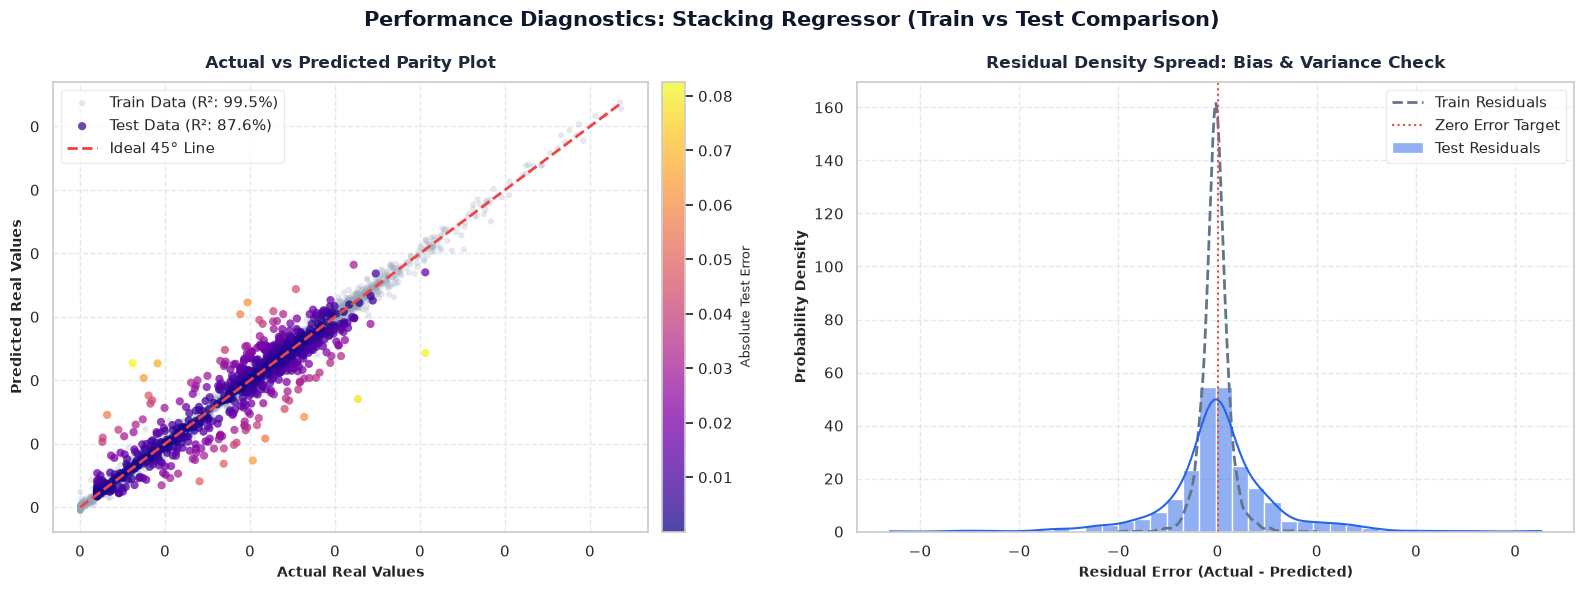

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,Stacking Regressor,99.50%,87.58%,+11.93%,0.00,0.01,0.00,0.01


In [118]:
evaluate_and_plot_model(
    model=stack,
    model_name="Stacking Regressor",
)

In [119]:
get_model_comparison_summary()

,Model Name,R2 Train (%),R2 Test (%),R2 Gap (%),MAE Train,MAE Test,RMSE Train,RMSE Test
0,CatBoost Regressor,99.41%,87.78%,+11.63%,0.00,0.01,0.00,0.01
1,Gradient Boosting Regressor,97.20%,87.71%,+9.49%,0.00,0.01,0.01,0.01
2,Stacking Regressor,99.50%,87.58%,+11.93%,0.00,0.01,0.00,0.01
3,Voting Regressor,98.41%,87.43%,+10.99%,0.00,0.01,0.01,0.01
4,LGBM Regressor,98.95%,86.98%,+11.97%,0.00,0.01,0.01,0.01
5,Random Forest Regressor,99.27%,86.27%,+13.00%,0.00,0.01,0.00,0.01
6,XGB Regressor,99.87%,85.87%,+14.00%,0.00,0.01,0.00,0.02
7,Linear Regression,89.95%,83.92%,+6.04%,0.01,0.01,0.02,0.02
8,Decision Tree Regressor,100.00%,81.45%,+18.55%,0.00,0.01,0.00,0.02
9,K Neighbors Regressor,73.39%,34.75%,+38.64%,0.02,0.02,0.03,0.03


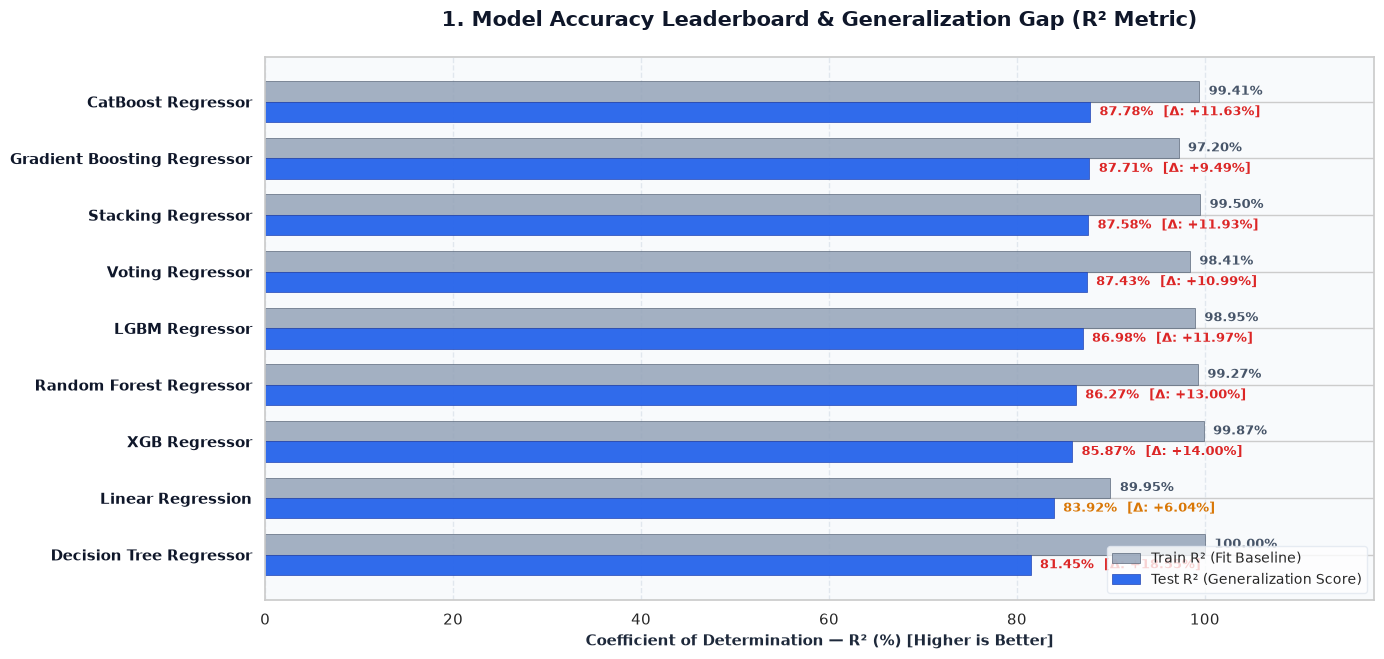

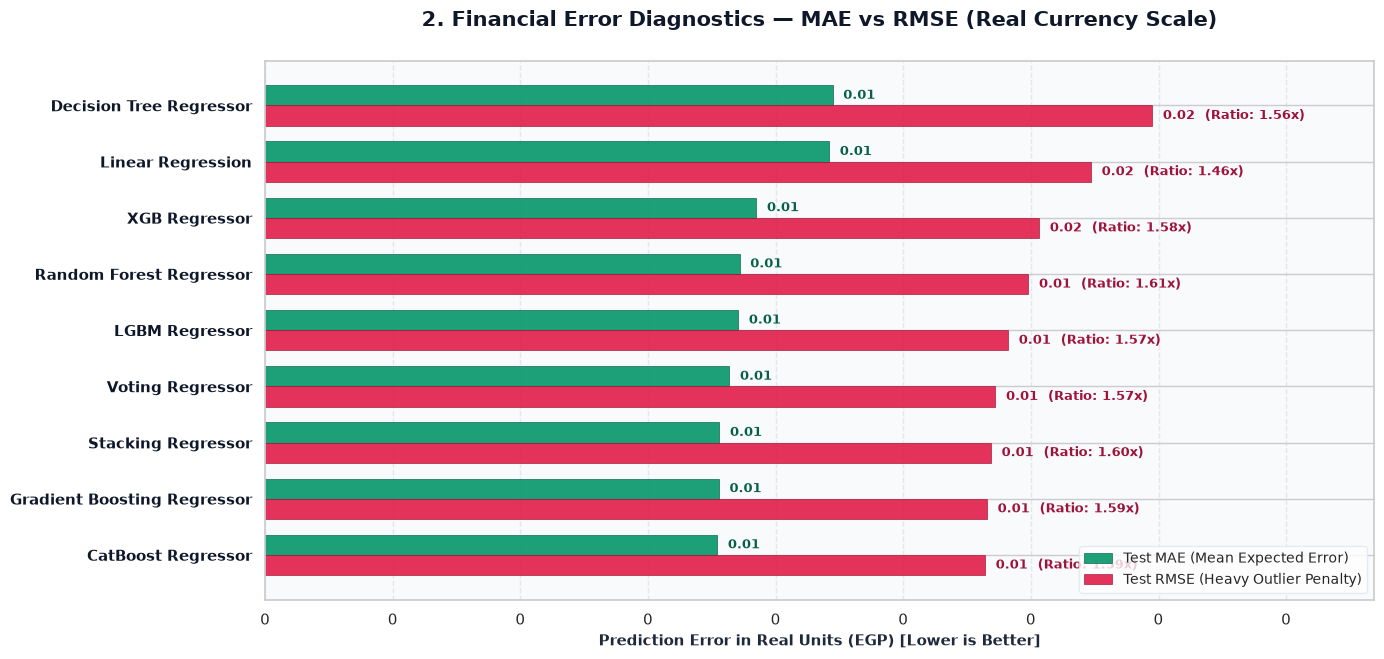

In [120]:

r2_test_col = 'R2 Test (%)' if 'R2 Test (%)' in model_comparison_df.columns else 'R2 Score'
r2_train_col = 'R2 Train (%)' if 'R2 Train (%)' in model_comparison_df.columns else r2_test_col
r2_gap_col = 'R2 Gap (%)' if 'R2 Gap (%)' in model_comparison_df.columns else None

mae_test_col = 'MAE Test' if 'MAE Test' in model_comparison_df.columns else 'MAE'
rmse_test_col = 'RMSE Test' if 'RMSE Test' in model_comparison_df.columns else 'RMSE'

df_valid = model_comparison_df[model_comparison_df[r2_test_col] > 35].copy()
df_r2_sorted = df_valid.sort_values(by=r2_test_col, ascending=True).reset_index(drop=True)


fig1, ax1 = plt.subplots(figsize=(14, max(6, len(df_r2_sorted) * 0.75)), facecolor='#FFFFFF')
ax1.set_facecolor('#F8FAFC')

y_indices = np.arange(len(df_r2_sorted))
bar_height = 0.36

bars_train = ax1.barh(
    y_indices + bar_height / 2, 
    df_r2_sorted[r2_train_col], 
    height=bar_height, 
    color='#94A3B8', 
    label='Train R² (Fit Baseline)', 
    edgecolor='#475569',
    linewidth=0.5,
    alpha=0.85
)

bars_test = ax1.barh(
    y_indices - bar_height / 2, 
    df_r2_sorted[r2_test_col], 
    height=bar_height, 
    color='#2563EB', 
    label='Test R² (Generalization Score)', 
    edgecolor='#1E40AF',
    linewidth=0.5,
    alpha=0.95
)

for i, (idx, row) in enumerate(df_r2_sorted.iterrows()):
    train_v = row[r2_train_col]
    test_v = row[r2_test_col]
    gap = row[r2_gap_col] if r2_gap_col else (train_v - test_v)
    
    ax1.text(
        train_v + 1.0, 
        y_indices[i] + bar_height / 2, 
        f'{train_v:.2f}%', 
        va='center', ha='left', fontsize=9, color='#475569', fontweight='semibold'
    )
    
    gap_color = '#059669' if gap <= 3.0 else ('#D97706' if gap <= 8.0 else '#DC2626')
    gap_badge = f'Δ: {gap:+.2f}%'
    
    ax1.text(
        test_v + 1.0, 
        y_indices[i] - bar_height / 2, 
        f'{test_v:.2f}%  [{gap_badge}]', 
        va='center', ha='left', fontsize=9.5, color=gap_color, fontweight='bold'
    )

ax1.set_yticks(y_indices)
ax1.set_yticklabels(df_r2_sorted['Model Name'], fontsize=11, fontweight='semibold', color='#0F172A')
ax1.set_title('1. Model Accuracy Leaderboard & Generalization Gap (R² Metric)', fontsize=15, fontweight='bold', pad=22, color='#0F172A')
ax1.set_xlabel('Coefficient of Determination — R² (%) [Higher is Better]', fontsize=11, fontweight='bold', color='#1E293B')
ax1.set_xlim(0, 118)
ax1.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1', axis='x')

ax1.legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#E2E8F0', fontsize=10)

plt.tight_layout()
plt.show()


df_err_sorted = df_valid.sort_values(by=rmse_test_col, ascending=True).reset_index(drop=True)

fig2, ax2 = plt.subplots(figsize=(14, max(6, len(df_err_sorted) * 0.75)), facecolor='#FFFFFF')
ax2.set_facecolor('#F8FAFC')

y_indices = np.arange(len(df_err_sorted))

bars_mae = ax2.barh(
    y_indices + bar_height / 2, 
    df_err_sorted[mae_test_col], 
    height=bar_height, 
    color='#059669', 
    label='Test MAE (Mean Expected Error)', 
    edgecolor='#065F46',
    linewidth=0.5,
    alpha=0.9
)

bars_rmse = ax2.barh(
    y_indices - bar_height / 2, 
    df_err_sorted[rmse_test_col], 
    height=bar_height, 
    color='#E11D48', 
    label='Test RMSE (Heavy Outlier Penalty)', 
    edgecolor='#9F1239',
    linewidth=0.5,
    alpha=0.9
)

max_err = df_err_sorted[rmse_test_col].max()
for i, (idx, row) in enumerate(df_err_sorted.iterrows()):
    mae_v = row[mae_test_col]
    rmse_v = row[rmse_test_col]
    ratio = (rmse_v / mae_v) if mae_v > 0 else 1.0
   
    ax2.text(
        mae_v + (max_err * 0.012), 
        y_indices[i] + bar_height / 2, 
        f'{mae_v:,.2f}', 
        va='center', ha='left', fontsize=9.5, color='#065F46', fontweight='semibold'
    )
    
    ax2.text(
        rmse_v + (max_err * 0.012), 
        y_indices[i] - bar_height / 2, 
        f'{rmse_v:,.2f}  (Ratio: {ratio:.2f}x)', 
        va='center', ha='left', fontsize=9.5, color='#9F1239', fontweight='bold'
    )

ax2.set_yticks(y_indices)
ax2.set_yticklabels(df_err_sorted['Model Name'], fontsize=11, fontweight='semibold', color='#0F172A')
ax2.set_title('2. Financial Error Diagnostics — MAE vs RMSE (Real Currency Scale)', fontsize=15, fontweight='bold', pad=25, color='#0F172A')
ax2.set_xlabel('Prediction Error in Real Units (EGP) [Lower is Better]', fontsize=11, fontweight='bold', color='#1E293B')

ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
ax2.set_xlim(0, max_err * 1.25)
ax2.grid(True, linestyle='--', alpha=0.5, color='#CBD5E1', axis='x')

ax2.legend(loc='lower right', frameon=True, facecolor='#FFFFFF', edgecolor='#E2E8F0', fontsize=10)

plt.tight_layout()
plt.show()

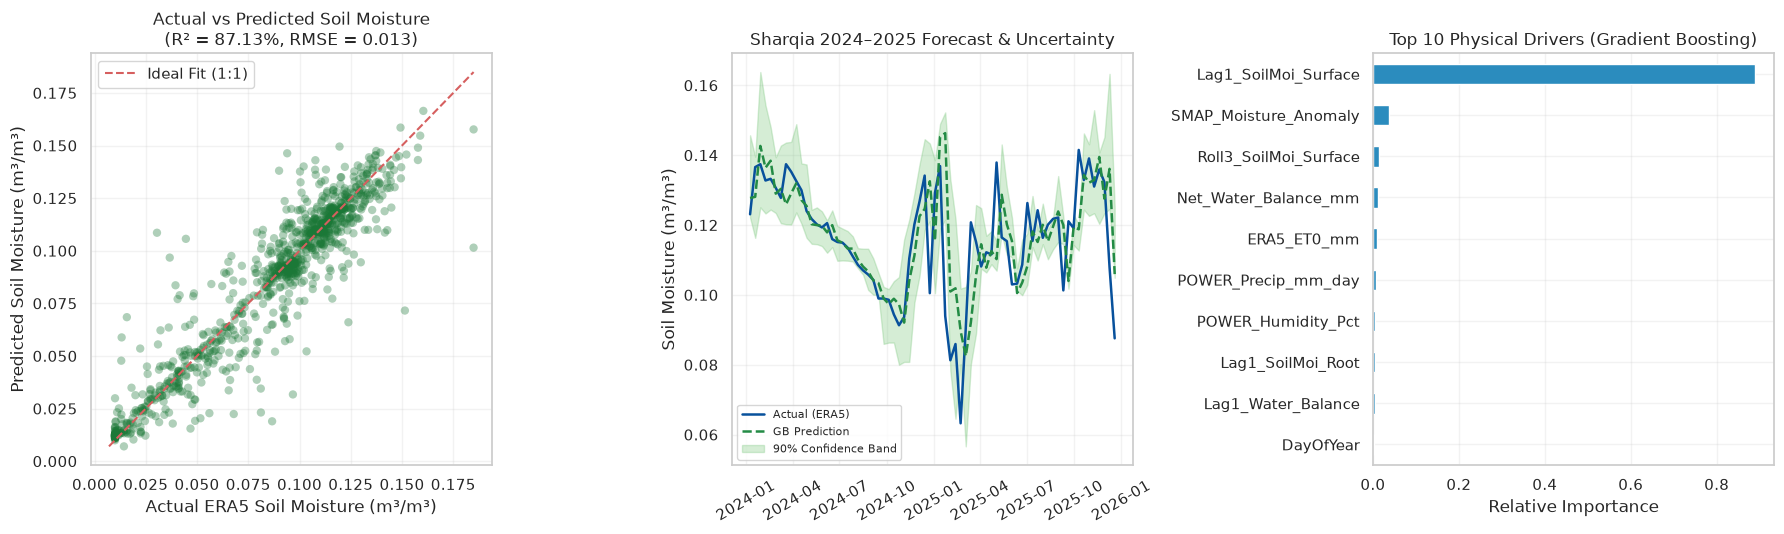

🎉 اكتملت جميع مهام العضو الثاني بنجاح تام!
📦 ملف الموديل المحفوظ: d:\vscode\NASA\DATA\models\soil_gb_model.joblib
📊 جدول المقارنة المحفوظ: d:\vscode\NASA\DATA\docs\model_comparison_metrics.csv
📈 لوحة الرسوم المحفوظة: d:\vscode\NASA\DATA\docs\model_validation_charts.png


In [125]:

BASE_DIR = r"d:\vscode\NASA\DATA"
MODEL_OUT_PATH = os.path.join(BASE_DIR, "models", "soil_gb_model.joblib")
METRICS_OUT_PATH = os.path.join(BASE_DIR, "docs", "model_comparison_metrics.csv")
CHART_OUT_PATH = os.path.join(BASE_DIR, "docs", "model_validation_charts.png")

os.makedirs(os.path.dirname(MODEL_OUT_PATH), exist_ok=True)
os.makedirs(os.path.dirname(METRICS_OUT_PATH), exist_ok=True)

benchmark_summary = get_model_comparison_summary()
benchmark_summary.data.to_csv(METRICS_OUT_PATH, index=False, encoding="utf-8-sig")


# 2. تدريب وحفظ حزمة النموذج الفائز (Gradient Boosting) + مجالات الثقة 90%
gb_mean = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)
gb_low = GradientBoostingRegressor(loss="quantile", alpha=0.05, n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)
gb_high = GradientBoostingRegressor(loss="quantile", alpha=0.95, n_estimators=200, learning_rate=0.05, max_depth=5, random_state=42)

gb_mean.fit(X_train, y_train)
gb_low.fit(X_train, y_train)
gb_high.fit(X_train, y_train)

pred_mean = gb_mean.predict(X_test)
pred_low = gb_low.predict(X_test)
pred_high = gb_high.predict(X_test)
unc_half = (pred_high - pred_low) / 2.0

artifact = {
    "model_mean": gb_mean,
    "model_lower": gb_low,
    "model_upper": gb_high,
    "features": list(X_train.columns),
    "target": "ERA5_SoilMoi_0_7cm_cm3",
    "r2_test": round(float(r2_score(y_test, pred_mean)), 4),
    "rmse_test": round(float(np.sqrt(mean_squared_error(y_test, pred_mean))), 5),
    "mae_test": round(float(mean_absolute_error(y_test, pred_mean)), 5),
    "mean_uncertainty": float(unc_half.mean()),
}
joblib.dump(artifact, MODEL_OUT_PATH)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

axes[0].scatter(y_test, pred_mean, alpha=0.35, color="#1b7837", edgecolors="none")
lims = [min(y_test.min(), pred_mean.min()), max(y_test.max(), pred_mean.max())]
axes[0].plot(lims, lims, "r--", lw=1.5, label="Ideal Fit (1:1)")
axes[0].set_title(f"Actual vs Predicted Soil Moisture\n(R² = {artifact['r2_test']*100:.2f}%, RMSE = {artifact['rmse_test']:.3f})")
axes[0].set_xlabel("Actual ERA5 Soil Moisture (m³/m³)")
axes[0].set_ylabel("Predicted Soil Moisture (m³/m³)")
axes[0].legend()
axes[0].grid(True, alpha=0.25)

sharqia_mask = (test_df["Governorate"] == "Sharqia").values
dates_sh = test_df.loc[sharqia_mask, "Date"]
axes[1].plot(dates_sh, y_test.values[sharqia_mask], label="Actual (ERA5)", color="#08519c", lw=1.8)
axes[1].plot(dates_sh, pred_mean[sharqia_mask], label="GB Prediction", color="#238b45", lw=1.8, linestyle="--")
axes[1].fill_between(dates_sh, pred_low[sharqia_mask], pred_high[sharqia_mask], color="#74c476", alpha=0.3, label="90% Confidence Band")
axes[1].set_title("Sharqia 2024–2025 Forecast & Uncertainty")
axes[1].set_ylabel("Soil Moisture (m³/m³)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.25)

importances = pd.Series(gb_mean.feature_importances_, index=X_train.columns).sort_values(ascending=True).tail(10)
importances.plot(kind="barh", ax=axes[2], color="#2b8cbe")
axes[2].set_title("Top 10 Physical Drivers (Gradient Boosting)")
axes[2].set_xlabel("Relative Importance")
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig(CHART_OUT_PATH, dpi=220)
plt.show()

print("=" * 75)
print("🎉 اكتملت جميع مهام العضو الثاني بنجاح تام!")
print(f"📦 ملف الموديل المحفوظ: {MODEL_OUT_PATH}")
print(f"📊 جدول المقارنة المحفوظ: {METRICS_OUT_PATH}")
print(f"📈 لوحة الرسوم المحفوظة: {CHART_OUT_PATH}")
print("=" * 75)